# 接单时的外卖晚到风险识别

本研究在骑手接单时（`grab_time`）预测订单是否晚于平台记录的预计送达时间（ETA），比较随机排序、距离规则、Logistic Regression 和 XGBoost 在有限监控容量下的识别表现。主标签 `y_0` 对应任何超过 ETA 的送达，`y_8` 用于检查较明显延迟下的敏感性。本研究评价历史订单上的风险排序与固定容量表现。

所有日期、小时和数据划分均使用北京时间（`Asia/Shanghai`）。模型输入限于按业务定义在接单时已产生的字段；实际送达、取餐等后续事件只用于标签或事后分析。ETA 提前量依据数据表中的记录回溯计算。

## 运行说明

在项目根目录安装 `requirements.txt` 中记录的依赖，然后从 `notebooks/` 目录启动 Jupyter，选择相同 Python 环境的内核并从头依次运行。当前相对路径要求内核工作目录为 `notebooks/`。

```bash
python -m pip install -r requirements.txt
cd notebooks
python -m jupyterlab food_delivery_analysis.ipynb
```

必需输入为 `../data/Meituan-INFORMS-TSL-Research-Challenge/all_waybill_info_meituan_0322.csv` 和 `../data/data_dictionary.csv`。运行环境记录为 Python 3.13.15、pandas 3.1.0、NumPy 2.5.4、scikit-learn 1.9.1、XGBoost 3.4.1、Matplotlib 3.11.2；这些版本取自本地 `lab` 环境。SHAP 贡献由 XGBoost 原生接口计算，无需另装 `shap`。

第 14–16 节在 `../results/` 写出主分析、三折滚动回测和分组种子敏感性结果，覆盖同名 CSV。文中数值对应随 notebook 保留的输出；更换数据或运行环境后，应以重新运行的结果更新说明。数据获取与使用条件见项目随附的 `License.txt`。本版于 2026 年 11 月 19 日顺序运行全部 62 个代码单元；代码断言及导出回读检查通过。


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_SEED = 42


In [2]:
# 相对路径以 notebooks/ 为工作目录。
CSV_PATH = Path("../data/Meituan-INFORMS-TSL-Research-Challenge/all_waybill_info_meituan_0322.csv")
DATA_DICT_PATH = Path("../data/data_dictionary.csv")


## 1. 数据准备

分析使用美团运单主表及项目数据字典。原始数据包含同一订单的不同派单记录；筛选已接单且关键时间有效的记录后，检查订单标识是否唯一，以订单为分析单位。


In [3]:
df_raw = pd.read_csv(CSV_PATH)

print("数据规模：", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes)


数据规模： (654343, 24)


,Unnamed: 0,dt,order_id,waybill_id,courier_id,da_id,is_courier_grabbed,is_weekend,estimate_arrived_time,is_prebook,poi_id,sender_lng,sender_lat,recipient_lng,recipient_lat,grab_lng,grab_lat,dispatch_time,grab_time,fetch_time,arrive_time,estimate_meal_prepare_time,order_push_time,platform_order_time
0,0,20221017,0,0,0,0,0,1,1665937978,0,0,174579111,45862631,174600135,45852786,0,0,1665936258,0,0,0,1665936779,1665936000,1665935996
1,1,20221017,1,1,1,1,1,1,1665937864,0,1,174529930,45905850,174522983,45898250,174530062,45906005,1665936734,1665936737,1665937344,1665937798,1665936845,1665936006,1665935995
2,2,20221017,2,2,2,2,1,0,1665939504,0,2,174532407,45861460,174547033,45891243,174548244,45870923,1665937484,1665937501,1665938346,1665939384,1665938007,1665937107,1665937097
3,3,20221017,3,3,3,0,1,0,1665939432,0,3,174559718,45868015,174595327,45886787,174560199,45867948,1665937394,1665937397,1665937830,1665939822,1665937634,1665937369,1665937028
4,4,20221017,4,4,4,0,1,0,1665938894,0,3,174559718,45868015,174534558,45867411,174554896,45865167,1665937394,1665937413,1665937710,1665938262,1665937694,1665937373,1665937092


Unnamed: 0                    int64
dt                            int64
order_id                      int64
waybill_id                    int64
courier_id                    int64
da_id                         int64
is_courier_grabbed            int64
is_weekend                    int64
estimate_arrived_time         int64
is_prebook                    int64
poi_id                        int64
sender_lng                    int64
sender_lat                    int64
recipient_lng                 int64
recipient_lat                 int64
grab_lng                      int64
grab_lat                      int64
dispatch_time                 int64
grab_time                     int64
fetch_time                    int64
arrive_time                   int64
estimate_meal_prepare_time    int64
order_push_time               int64
platform_order_time           int64
dtype: object

In [4]:
misssing_table = pd.DataFrame({
    'missing_count': df_raw.isna().sum(),
    'missing_rate': df_raw.isna().mean()
})

display(misssing_table)


,missing_count,missing_rate
Unnamed: 0,0,0.0
dt,0,0.0
order_id,0,0.0
waybill_id,0,0.0
courier_id,0,0.0
da_id,0,0.0
is_courier_grabbed,0,0.0
is_weekend,0,0.0
estimate_arrived_time,0,0.0
is_prebook,0,0.0


In [5]:
data_dict = pd.read_csv(DATA_DICT_PATH)

display(data_dict)


,原始字段,中文含义与表示,本项目用途
0,Unnamed: 0,导出行索引，无业务含义,删除，不当作特征
1,dt,记录日期码，形如 YYYYMMDD；不直接等同于下单日期,描述与日期核对；正式切分使用接单日期
2,order_id,匿名订单标识,关联同一订单的多次运单，订单级去重
3,waybill_id,匿名运单标识,区分派单记录；不直接建模
4,courier_id,该运单被派给的匿名骑手标识,骑手分组、历史特征；不按数值大小解释
5,da_id,商圈或运营区域标识,分组分析及类别特征；不是严格互斥的纯地理分区
6,is_courier_grabbed,是否接受运单，1 接受、0 未接受,筛选已接单样本；筛选后不作为特征
7,is_weekend,创建日是否周末，0/1,描述性分组；原始标记与接单日周末需区分，首轮模型暂不使用
8,estimate_arrived_time,平台记录的承诺/预计送达时刻，Unix 秒,生成标签和回溯提前量；历史版本未确认，不作核心输入
9,is_prebook,是否预约订单，0/1,描述、分层和模型特征


## 2. 数据清洗

原始数据共 654,343 条运单记录，其中 568,546 条已接单。排除 1 条接单、送达或 ETA 时间无效的记录后，保留 568,545 笔订单，订单 ID 无重复。其余非正时间戳转为缺失，负阶段耗时不参与统计；坐标按字段尺度转换并检查取值范围。


In [6]:
# 保留已接单且接单、送达、ETA 时间有效的记录，并核对订单唯一性。
accepted_mask = df_raw["is_courier_grabbed"].eq(1)

required_time_cols = [
    "grab_time",
    "arrive_time",
    "estimate_arrived_time"
]

valid_time_mask = (
    df_raw[required_time_cols]
    .gt(0)
    .all(axis=1)
)

df_clean = (
    df_raw.loc[accepted_mask & valid_time_mask]
    .drop(columns=["Unnamed: 0"])
    .copy()
)

cleaning_summary = pd.Series({
    "原始运单数": len(df_raw),
    "已接单运单数": accepted_mask.sum(),
    "已接单但关键时间无效": (
        accepted_mask & ~valid_time_mask
    ).sum(),
    "保留的完成订单数": len(df_clean),
    "重复订单记录数": df_clean["order_id"].duplicated().sum()
}, name="数量")

display(cleaning_summary.to_frame())


,数量
原始运单数,654343
已接单运单数,568546
已接单但关键时间无效,1
保留的完成订单数,568545
重复订单记录数,0


In [7]:
# 非正时间戳视为缺失；其余字段保持原值。
time_cols = [
    "platform_order_time",
    "order_push_time",
    "dispatch_time",
    "grab_time",
    "fetch_time",
    "arrive_time",
    "estimate_arrived_time",
    "estimate_meal_prepare_time"
]

df_clean[time_cols] = (
    df_clean[time_cols]
    .mask(df_clean[time_cols].le(0))
)

time_missing = df_clean[time_cols].isna().sum()

display(time_missing[time_missing > 0].to_frame("缺失数量"))


,缺失数量
dispatch_time,1
estimate_meal_prepare_time,9874


In [8]:
# Unix 秒先按 UTC 解析，再转换为北京时间。
for col in time_cols:
    df_clean[f"{col}_dt"] = (
        pd.to_datetime(
            df_clean[col],
            unit="s",
            utc=True,
            errors="coerce"
        )
        .dt.tz_convert("Asia/Shanghai")
    )

display(
    df_clean[[
        "order_id",
        "platform_order_time_dt",
        "order_push_time_dt",
        "grab_time_dt",
        "arrive_time_dt"
    ]].head()
)


,order_id,platform_order_time_dt,order_push_time_dt,grab_time_dt,arrive_time_dt
1,1,2022-10-16 23:59:55+08:00,2022-10-17 00:00:06+08:00,2022-10-17 00:12:17+08:00,2022-10-17 00:29:58+08:00
2,2,2022-10-17 00:18:17+08:00,2022-10-17 00:18:27+08:00,2022-10-17 00:25:01+08:00,2022-10-17 00:56:24+08:00
3,3,2022-10-17 00:17:08+08:00,2022-10-17 00:22:49+08:00,2022-10-17 00:23:17+08:00,2022-10-17 01:03:42+08:00
4,4,2022-10-17 00:18:12+08:00,2022-10-17 00:22:53+08:00,2022-10-17 00:23:33+08:00,2022-10-17 00:37:42+08:00
5,5,2022-10-17 00:39:59+08:00,2022-10-17 00:40:03+08:00,2022-10-17 00:45:41+08:00,2022-10-17 01:14:56+08:00


In [9]:
# 核查业务事件的先后顺序；此处仅统计异常，不删除记录。
time_order_issues = pd.Series({
    "进入调度早于下单": (
        df_clean["order_push_time"]
        < df_clean["platform_order_time"]
    ).sum(),

    "派单早于进入调度": (
        df_clean["dispatch_time"]
        < df_clean["order_push_time"]
    ).sum(),

    "接单早于派单": (
        df_clean["grab_time"]
        < df_clean["dispatch_time"]
    ).sum(),

    "取餐早于接单": (
        df_clean["fetch_time"]
        < df_clean["grab_time"]
    ).sum(),

    "送达早于取餐": (
        df_clean["arrive_time"]
        < df_clean["fetch_time"]
    ).sum()
}, name="异常数量")

display(time_order_issues.to_frame())


,异常数量
进入调度早于下单,0
派单早于进入调度,0
接单早于派单,0
取餐早于接单,0
送达早于取餐,0


In [10]:
# 坐标按百万分之一度转换；无效坐标置为缺失，原始字段保留。
for prefix in ["sender", "recipient", "grab"]:
    lng = df_clean[f"{prefix}_lng"] / 1_000_000
    lat = df_clean[f"{prefix}_lat"] / 1_000_000

    valid_location = (
        lng.between(-180, 180)
        & lat.between(-90, 90)
        & lng.ne(0)
        & lat.ne(0)
    )

    df_clean[f"{prefix}_lng_deg"] = lng.where(valid_location)
    df_clean[f"{prefix}_lat_deg"] = lat.where(valid_location)

coordinate_cols = [
    "sender_lng_deg", "sender_lat_deg",
    "recipient_lng_deg", "recipient_lat_deg",
    "grab_lng_deg", "grab_lat_deg"
]

display(df_clean[coordinate_cols].head())
display(
    df_clean[coordinate_cols]
    .isna()
    .sum()
    .to_frame("坐标缺失数量")
)


,sender_lng_deg,sender_lat_deg,recipient_lng_deg,recipient_lat_deg,grab_lng_deg,grab_lat_deg
1,174.529930,45.905850,174.522983,45.898250,174.530062,45.906005
2,174.532407,45.861460,174.547033,45.891243,174.548244,45.870923
3,174.559718,45.868015,174.595327,45.886787,174.560199,45.867948
4,174.559718,45.868015,174.534558,45.867411,174.554896,45.865167
5,174.542688,45.920329,174.530185,45.921310,174.526338,45.912309


,坐标缺失数量
sender_lng_deg,0
sender_lat_deg,0
recipient_lng_deg,0
recipient_lat_deg,0
grab_lng_deg,0
grab_lat_deg,0


### 标签定义

`delay_sec = arrive_time - estimate_arrived_time`。主标签 `y_0 = 1` 表示偏差严格大于 0；敏感性标签 `y_8 = 1` 表示偏差严格大于 480 秒。恰好在 ETA 送达不属于 `y_0` 正例，恰好晚 8 分钟不属于 `y_8` 正例。

`y_0` 回答能否识别所有超过 ETA 的订单；`y_8` 检验关注更明显延迟时，模型是否仍优于基准。精确率和覆盖率均在同一标签定义下比较。


In [11]:
# 标签使用严格大于：恰好到 ETA 或恰好晚 8 分钟不计为对应正例。
df_clean["delay_sec"] = (
    df_clean["arrive_time"] - df_clean["estimate_arrived_time"]
)

df_clean["y_0"] = df_clean["delay_sec"].gt(0).astype("int8")
df_clean["y_8"] = df_clean["delay_sec"].gt(480).astype("int8")

label_cols = ["y_0", "y_8"]

label_summary = pd.DataFrame({
    "正例数": df_clean[label_cols].sum(),
    "正例比例(%)": df_clean[label_cols].mean() * 100,
})

display(label_summary.round(2))
display(df_clean[["order_id", "delay_sec", "y_0", "y_8"]].head())


,正例数,正例比例(%)
y_0,85328,15.01
y_8,10899,1.92


,order_id,delay_sec,y_0,y_8
1,1,-66,0,0
2,2,-120,0,0
3,3,390,1,0
4,4,-632,0,0
5,5,-4,0,0


In [12]:
# 负阶段耗时置为缺失；各阶段分别统计有效样本。
stage_pairs = {
    "order_to_push_min": ("platform_order_time", "order_push_time"),
    "push_to_dispatch_min": ("order_push_time", "dispatch_time"),
    "dispatch_to_grab_min": ("dispatch_time", "grab_time"),
    "grab_to_fetch_min": ("grab_time", "fetch_time"),
    "fetch_to_arrive_min": ("fetch_time", "arrive_time"),
    "order_to_arrive_min": ("platform_order_time", "arrive_time"),
}

for name, (start, end) in stage_pairs.items():
    seconds = df_clean[end] - df_clean[start]
    df_clean[name] = seconds.where(seconds.ge(0)) / 60

stage_cols = list(stage_pairs)

stage_summary = df_clean[stage_cols].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
).T
stage_summary["missing"] = df_clean[stage_cols].isna().sum()

display(
    stage_summary[
        ["count", "missing", "mean", "25%", "50%", "75%", "90%"]
    ].round(2)
)


,count,missing,mean,25%,50%,75%,90%
order_to_push_min,568545.0,0,2.50,0.13,0.20,0.40,2.95
push_to_dispatch_min,568544.0,1,6.84,0.37,1.77,5.38,9.10
dispatch_to_grab_min,568544.0,1,0.44,0.12,0.18,0.33,0.70
grab_to_fetch_min,568545.0,0,10.26,5.67,9.03,13.45,18.40
fetch_to_arrive_min,568545.0,0,15.46,8.18,13.45,20.80,28.62
order_to_arrive_min,568545.0,0,35.49,21.23,28.50,38.03,48.98


各阶段耗时基于清洗后的 568,545 笔订单分别统计，缺失值不参与分位数计算。

| 阶段 | 中位数（分钟） | P90（分钟） | 缺失数 |
|---|---:|---:|---:|
| 下单 → 进入调度 | 0.20 | 2.95 | 0 |
| 进入调度 → 派单 | 1.77 | 9.10 | 1 |
| 派单 → 接单 | 0.18 | 0.70 | 1 |
| 接单 → 取餐 | 9.03 | 18.40 | 0 |
| 取餐 → 送达 | 13.45 | 28.62 | 0 |
| 下单 → 送达 | 28.50 | 48.98 | 0 |

接单后两个阶段的中位耗时较长。各阶段分位数分别计算，总耗时分位数由逐单总耗时直接计算。取餐和送达后的耗时仅用于事后分析。


In [13]:
# 按 Haversine 公式估算地理距离，单位为公里。
def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    )
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


df_clean["merchant_to_customer_km"] = haversine_km(
    df_clean["sender_lat_deg"],
    df_clean["sender_lng_deg"],
    df_clean["recipient_lat_deg"],
    df_clean["recipient_lng_deg"],
)

df_clean["rider_to_merchant_km"] = haversine_km(
    df_clean["grab_lat_deg"],
    df_clean["grab_lng_deg"],
    df_clean["sender_lat_deg"],
    df_clean["sender_lng_deg"],
)

distance_cols = ["merchant_to_customer_km", "rider_to_merchant_km"]

distance_summary = df_clean[distance_cols].describe(
    percentiles=[0.5, 0.9, 0.99]
).T
distance_summary["missing"] = df_clean[distance_cols].isna().sum()
distance_summary["zero"] = df_clean[distance_cols].eq(0).sum()

display(distance_summary[["50%", "90%", "99%", "missing", "zero"]].round(3))
display(df_clean[["order_id"] + distance_cols].head().round(3))


,50%,90%,99%,missing,zero
merchant_to_customer_km,1.469,2.796,4.986,0,6
rider_to_merchant_km,0.474,1.285,2.461,0,0


,order_id,merchant_to_customer_km,rider_to_merchant_km
1,1,1.002,0.020
2,2,3.500,1.616
3,3,3.458,0.038
4,4,1.949,0.490
5,5,0.973,1.548


| 距离 | 中位数（公里） | P90（公里） | P99（公里） | 缺失数 | 零距离数 |
|---|---:|---:|---:|---:|---:|
| 商家 → 顾客 | 1.469 | 2.796 | 4.986 | 0 | 6 |
| 骑手接单位置 → 商家 | 0.474 | 1.285 | 2.461 | 0 | 0 |

距离由匿名化坐标按 Haversine 公式估算，描述两点间的近似地理距离；实际行驶距离和耗时还取决于道路网络、绕行及交通状况。坐标通过取值范围检查，6 笔商家与顾客坐标重合的记录保留。


## 3. 开发集分组与时间外测试

主方案将 2022 年 10 月 17–22 日接单、且在 23 日零点前已送达的订单作为历史开发集。按接单日期分层，每天随机抽取约 20% 的骑手组用于验证，其余用于训练；同一“骑手 × 接单日期”的订单整体进入同一集合。分组种子固定为 42，划分不使用标签。每个日期选取的验证组数向上取整，订单数比例围绕 20% 随分组规模变化。

| 集合 | 接单日期 | 标签可得性 | 订单数 | 周六订单数 |
|---|---|---|---:|---:|
| 训练 | 10 月 17–22 日，每日约 80% 骑手组 | 10 月 23 日零点前已送达 | 338,252 | 62,132 |
| 验证 | 10 月 17–22 日，每日约 20% 骑手组 | 10 月 23 日零点前已送达 | 84,756 | 15,098 |
| 时间外测试 | 10 月 23–24 日，整日保留 | 使用事后可得的有效标签 | 145,068 | 0（含 77,719 笔周日订单） |

开发窗口有 407 笔订单因标签截止规则被排除，另有 62 笔清洗后订单在八天接单窗口之外。最终使用 568,076 笔订单，三组订单 ID 不重叠，训练与验证也不共享骑手日组。

这一方案使训练和验证同时覆盖五个工作日与周六，模型拟合和阈值确定均使用六个日期的历史样本。同一骑手当日订单整体分组，跨日骑手、商户和区域关联仍保留在数据中。验证订单与训练订单来自相同历史日期，因此内部验证衡量历史期留组表现；面向未来日期的表现由整日保留的 23–24 日测试和第 15 节的滚动回测评价。

模型和预处理仅在训练部分拟合，容量阈值只由验证分数确定；选定阈值后保持模型和预处理器固定，使测试分数沿用验证时的计算方式。特征及模型超参数沿用原设定，第 16 节另检查分组种子 43、44，主结果始终使用种子 42。

数据覆盖一个周末，本次结果对应所观察的八天业务窗口。原测试日期的结果已在早先分析中查看，本次采用回顾性设计评估验证方案。跨周稳定性和日历效应需要更多独立日期检验。三折回测按自然日设置窗口，各窗口的订单数随当日业务量变化。时间顺序评估原则参见 [scikit-learn 官方说明](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)。


In [14]:
# 按北京时间接单日期统计，保留时区以匹配划分边界。
df_clean["grab_date"] = df_clean["grab_time_dt"].dt.normalize()

daily_counts = df_clean["grab_date"].value_counts().sort_index()

display(daily_counts.to_frame("订单数"))


,订单数
grab_date,
2022-10-17 00:00:00+08:00,66835
2022-10-18 00:00:00+08:00,69095
2022-10-19 00:00:00+08:00,68852
2022-10-20 00:00:00+08:00,68816
2022-10-21 00:00:00+08:00,72180
2022-10-22 00:00:00+08:00,77637
2022-10-23 00:00:00+08:00,77719
2022-10-24 00:00:00+08:00,67349
2022-10-25 00:00:00+08:00,62


In [15]:
# 历史开发期与时间外测试期按接单日期隔离。
tz = "Asia/Shanghai"
development_start = pd.Timestamp("2022-10-17", tz=tz)
test_start = pd.Timestamp("2022-10-23", tz=tz)
test_end = pd.Timestamp("2022-10-25", tz=tz)
validation_fraction = 0.20

development_window = (
    df_clean["grab_date"].ge(development_start)
    & df_clean["grab_date"].lt(test_start)
)
test_window = df_clean["grab_date"].ge(test_start) & df_clean["grab_date"].lt(test_end)
# 两个开发子集均只使用测试开始前已送达、标签已知的订单。
development_mask = development_window & df_clean["arrive_time_dt"].lt(test_start)
df_development = df_clean.loc[development_mask].copy()
df_test = df_clean.loc[test_window].copy()


def split_development(frame, validation_fraction=0.20, random_state=42):
    """按日期分层，将同一骑手同一天的订单整体分至训练或验证。"""
    assert 0 < validation_fraction < 1
    assert frame["order_id"].is_unique
    assert frame[["courier_id", "grab_date"]].notna().all().all()
    rng_split = np.random.default_rng(random_state)
    validation_mask = pd.Series(False, index=frame.index)
    for _, day in frame.groupby("grab_date", sort=True):
        courier_groups = np.sort(day["courier_id"].unique())
        n_validation = int(np.ceil(validation_fraction * len(courier_groups)))
        assert 0 < n_validation < len(courier_groups)
        selected = rng_split.permutation(courier_groups)[:n_validation]
        validation_mask.loc[day.index] = day["courier_id"].isin(selected)
    train = frame.loc[~validation_mask].copy()
    validation = frame.loc[validation_mask].copy()
    train_groups = pd.MultiIndex.from_frame(train[["grab_date", "courier_id"]])
    validation_groups = pd.MultiIndex.from_frame(validation[["grab_date", "courier_id"]])
    assert train_groups.intersection(validation_groups).empty
    assert len(train) + len(validation) == len(frame)
    assert set(train["grab_date"]) == set(validation["grab_date"]) == set(frame["grab_date"])
    return train, validation


df_train, df_val = split_development(df_development, validation_fraction, RANDOM_SEED)
assert df_train["arrive_time_dt"].lt(test_start).all()
assert df_val["arrive_time_dt"].lt(test_start).all()
assert df_train["grab_time_dt"].lt(df_test["grab_time_dt"].min()).all()
assert df_val["grab_time_dt"].lt(df_test["grab_time_dt"].min()).all()
used_orders = pd.concat([df_train["order_id"], df_val["order_id"], df_test["order_id"]])
assert used_orders.is_unique


In [16]:
split_summary = pd.Series({
    "开发期按接单日期归入": int(development_window.sum()),
    "开发期因标签截止排除": int((development_window & ~development_mask).sum()),
    "开发期最终使用": len(df_development),
    "训练集": len(df_train),
    "验证集": len(df_val),
    "测试集": len(df_test),
    "接单日期在窗口外": int((~(development_window | test_window)).sum()),
}, name="订单数")
display(split_summary.to_frame())

# 同时核查每日样本量、骑手日分组数与标签比例。
balance_rows = []
for split, frame in [("Train", df_train), ("Validation", df_val), ("Test", df_test)]:
    for date, day in frame.groupby("grab_date", sort=True):
        balance_rows.append({
            "split": split,
            "date": date.strftime("%Y-%m-%d"),
            "weekday": date.day_name(),
            "accept_weekend": int(date.dayofweek >= 5),
            "orders": len(day),
            "courier_day_groups": day["courier_id"].nunique(),
            "late_n": int(day["y_0"].sum()),
            "late_pct": 100 * day["y_0"].mean(),
            "late_8_pct": 100 * day["y_8"].mean(),
            "prebook_pct": 100 * day["is_prebook"].mean(),
        })
main_split_balance = pd.DataFrame(balance_rows)
assert main_split_balance.loc[main_split_balance["split"].eq("Train"), "accept_weekend"].eq(1).any()
assert main_split_balance.loc[main_split_balance["split"].eq("Validation"), "accept_weekend"].eq(1).any()
display(main_split_balance.round(2))
print(f"三个集合共使用 {len(used_orders):,} 笔，订单 ID 无重复；训练与验证的骑手日分组不重叠。")


三个集合共使用 568,076 笔，订单 ID 无重复；训练与验证的骑手日分组不重叠。


,订单数
开发期按接单日期归入,423415
开发期因标签截止排除,407
开发期最终使用,423008
训练集,338252
验证集,84756
测试集,145068
接单日期在窗口外,62


,split,date,weekday,accept_weekend,orders,courier_day_groups,late_n,late_pct,late_8_pct,prebook_pct
0,Train,2022-10-17,Monday,0,53277,2848,7083,13.29,1.74,3.83
1,Train,2022-10-18,Tuesday,0,55013,2903,8510,15.47,1.90,4.03
2,Train,2022-10-19,Wednesday,0,55251,2931,8298,15.02,1.85,4.35
3,Train,2022-10-20,Thursday,0,55168,2936,8070,14.63,1.71,4.12
4,Train,2022-10-21,Friday,0,57411,2936,9020,15.71,1.93,3.95
5,Train,2022-10-22,Saturday,1,62132,2905,9241,14.87,1.91,3.58
6,Validation,2022-10-17,Monday,0,13558,712,1863,13.74,1.64,4.05
7,Validation,2022-10-18,Tuesday,0,14082,726,2307,16.38,2.14,4.13
8,Validation,2022-10-19,Wednesday,0,13601,733,2012,14.79,2.03,4.16
9,Validation,2022-10-20,Thursday,0,13648,734,2002,14.67,2.03,4.19


## 4. 训练集描述性分析


In [17]:
n_train = len(df_train)

sample_overview = pd.Series({
    "订单数": n_train,
    "最早接单日期": df_train["grab_date"].min().strftime("%Y-%m-%d"),
    "最晚接单日期": df_train["grab_date"].max().strftime("%Y-%m-%d"),
    "骑手数": df_train["courier_id"].nunique(),
    "商家数": df_train["poi_id"].nunique(),
    "运营区域数": df_train["da_id"].nunique(),
}, name="训练集")

binary_cols = ["is_prebook", "y_0", "y_8"]
positive_counts = df_train[binary_cols].eq(1).sum()

binary_summary = pd.DataFrame({
    "数量": positive_counts,
    "占训练集比例(%)": positive_counts / n_train * 100,
})

display(sample_overview.to_frame())
display(binary_summary.round(2))


,训练集
订单数,338252
最早接单日期,2022-10-17
最晚接单日期,2022-10-22
骑手数,4637
商家数,4780
运营区域数,23


,数量,占训练集比例(%)
is_prebook,13422,3.97
y_0,50222,14.85
y_8,6238,1.84


训练集包含 338,252 笔订单，涉及 4,637 名骑手、4,780 家商户和 23 个运营区域。以下比例均以训练集订单数为分母。

| 条件 | 数量 | 占训练集比例 |
|---|---:|---:|
| 预约订单 `is_prebook=1` | 13,422 | 3.97% |
| 超过 ETA，`y_0=1` | 50,222 | 14.85% |
| 超过 ETA 8 分钟，`y_8=1` | 6,238 | 1.84% |

两个标签的正例比例均较低，尤其是 `y_8`。模型比较以排序质量和有限监控容量下的精确率、覆盖率为主。


In [18]:
# 缺失率以训练集总数为分母；保留六位小数以显示单笔缺失。
missing_count = df_train.isna().sum()

missing_summary = pd.DataFrame({
    "缺失数": missing_count,
    "缺失率(%)": missing_count / n_train * 100,
}).sort_values("缺失数", ascending=False)

has_missing = missing_summary["缺失数"].gt(0)
display(missing_summary.loc[has_missing].round(6))


,缺失数,缺失率(%)
estimate_meal_prepare_time_dt,5866,1.734210
estimate_meal_prepare_time,5866,1.734210
dispatch_time_dt,1,0.000296
dispatch_to_grab_min,1,0.000296
push_to_dispatch_min,1,0.000296
dispatch_time,1,0.000296


In [19]:
# 描述性统计使用副本；送达偏差和 ETA 提前量仅用于事后分析。
train_numeric = df_train[stage_cols + distance_cols].copy()

train_numeric["order_to_grab_min"] = (
    df_train["grab_time"] - df_train["platform_order_time"]
) / 60

train_numeric["push_to_grab_min"] = (
    df_train["grab_time"] - df_train["order_push_time"]
) / 60

train_numeric["delay_min"] = df_train["delay_sec"] / 60

train_numeric["lead_time_min"] = (
    df_train["estimate_arrived_time"] - df_train["grab_time"]
) / 60

numeric_summary = train_numeric.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).T

numeric_summary.insert(
    0, "missing", n_train - numeric_summary["count"].astype(int)
)
display(numeric_summary.round(3))

late_minutes = train_numeric.loc[df_train["y_0"].eq(1), "delay_min"]
display(
    late_minutes.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
    .round(3)
    .to_frame("仅晚到订单的晚到分钟数")
)


,missing,count,mean,std,min,25%,50%,75%,90%,95%,max
order_to_push_min,0,338252.0,2.511,54.323,0.017,0.133,0.200,0.383,2.900,5.283,9828.300
push_to_dispatch_min,1,338251.0,6.939,58.208,0.000,0.367,1.717,5.333,9.050,13.417,10292.750
dispatch_to_grab_min,1,338251.0,0.433,1.359,0.000,0.117,0.183,0.333,0.700,1.333,319.767
grab_to_fetch_min,0,338252.0,10.210,6.739,0.033,5.650,9.000,13.367,18.283,21.783,614.950
fetch_to_arrive_min,0,338252.0,15.380,9.491,1.017,8.150,13.367,20.683,28.467,33.433,342.900
order_to_arrive_min,0,338252.0,35.475,81.650,1.967,21.117,28.300,37.833,48.783,57.367,10336.483
merchant_to_customer_km,0,338252.0,1.602,1.004,0.000,0.877,1.467,2.175,2.790,3.243,17.358
rider_to_merchant_km,0,338252.0,0.596,0.531,0.000,0.206,0.468,0.825,1.276,1.630,13.361
order_to_grab_min,0,338252.0,9.885,79.746,0.083,1.117,3.350,6.700,10.900,17.650,10293.467
push_to_grab_min,0,338252.0,7.374,58.242,0.017,0.617,2.217,5.817,9.400,14.500,10293.117


,仅晚到订单的晚到分钟数
count,50222.000
mean,4.760
std,6.530
min,0.017
25%,1.433
50%,3.267
75%,5.983
90%,9.550
95%,14.716
max,356.300


| 变量 | 均值 | 中位数 | P90 |
|---|---:|---:|---:|
| 下单至送达（分钟） | 35.48 | 28.30 | 48.78 |
| 接单至取餐（分钟） | 10.21 | 9.00 | 18.28 |
| 商家至顾客距离（公里） | 1.60 | 1.47 | 2.79 |
| 骑手接单位置至商家距离（公里） | 0.60 | 0.47 | 1.28 |
| 全体订单的到达偏差（分钟） | -8.09 | -8.17 | 1.93 |
| 仅晚到订单的晚到时长（分钟） | 4.76 | 3.27 | 9.55 |

训练集下单至送达耗时的均值高于中位数，分布存在较长右尾。到达偏差定义为实际送达时间减去记录 ETA；其负中位数表示超过一半的订单提前送达。


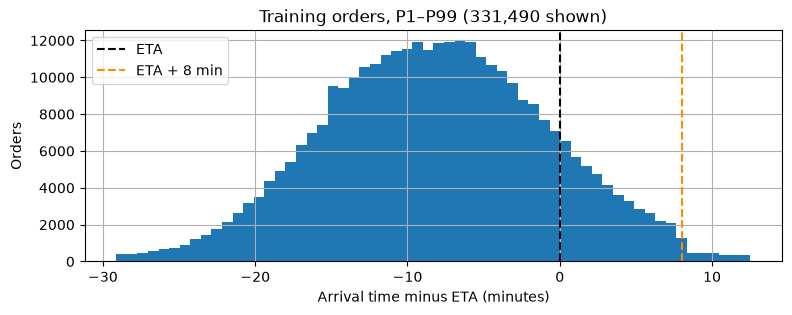

In [20]:
# 仅将直方图显示样本限制在 P1–P99，不改变建模数据。
delay_min = train_numeric["delay_min"]
lower, upper = delay_min.quantile([0.01, 0.99])
visible = delay_min.loc[delay_min.between(lower, upper)]

ax = visible.hist(bins=60, figsize=(9, 3))

ax.axvline(0, color="black", linestyle="--", label="ETA")
ax.axvline(8, color="darkorange", linestyle="--", label="ETA + 8 min")
ax.set_xlabel("Arrival time minus ETA (minutes)")
ax.set_ylabel("Orders")
ax.set_title(f"Training orders, P1–P99 ({len(visible):,} shown)")
ax.legend()
plt.show()


In [21]:
# 统计训练集类别构成；距离区间左闭右开。
category_columns = {
    "预约类型": df_train["is_prebook"].map({0: "非预约", 1: "预约"}),

    "接单日期": df_train["grab_date"].dt.strftime("%Y-%m-%d"),
    "接单小时": df_train["grab_time_dt"].dt.hour,
    "运营区域": df_train["da_id"],

    "商家至顾客距离档": pd.cut(
        df_train["merchant_to_customer_km"],
        bins=[0, 1, 2, 3, 5, np.inf],
        labels=["[0, 1)", "[1, 2)", "[2, 3)", "[3, 5)", "[5, ∞)"],
        right=False,
    ),
}

freq_tables = {}

for name, values in category_columns.items():
    # 保留缺失类别，使频数合计与训练样本数一致。
    counts = values.value_counts(sort=False, dropna=False).sort_index()

    freq_tables[name] = pd.DataFrame({
        "订单数": counts,
        "订单占比(%)": counts / n_train * 100,
    })

display(freq_tables["预约类型"].round(2))
display(freq_tables["接单日期"].round(2))
display(freq_tables["商家至顾客距离档"].round(2))

display(
    freq_tables["接单小时"]
    .nlargest(3, "订单数")
    .round(2)
)

display(
    freq_tables["运营区域"]
    .nlargest(3, "订单数")
    .round(2)
)


,订单数,订单占比(%)
is_prebook,,
非预约,324830,96.03
预约,13422,3.97


,订单数,订单占比(%)
grab_date,,
2022-10-17,53277,15.75
2022-10-18,55013,16.26
2022-10-19,55251,16.33
2022-10-20,55168,16.31
2022-10-21,57411,16.97
2022-10-22,62132,18.37


,订单数,订单占比(%)
merchant_to_customer_km,,
"[0, 1)",101439,29.99
"[1, 2)",134357,39.72
"[2, 3)",78582,23.23
"[3, 5)",20606,6.09
"[5, ∞)",3268,0.97


,订单数,订单占比(%)
grab_time_dt,,
11,59032,17.45
18,39945,11.81
12,36529,10.80


,订单数,订单占比(%)
da_id,,
0,68185,20.16
9,37993,11.23
5,37195,11.00


训练集的商家至顾客距离主要集中在 2 公里以内，占 69.71%；其中 [1, 2) 公里有 134,357 笔，占 39.72%。接单量最高的小时为北京时间 11:00–11:59，共 59,032 笔，占 17.45%。


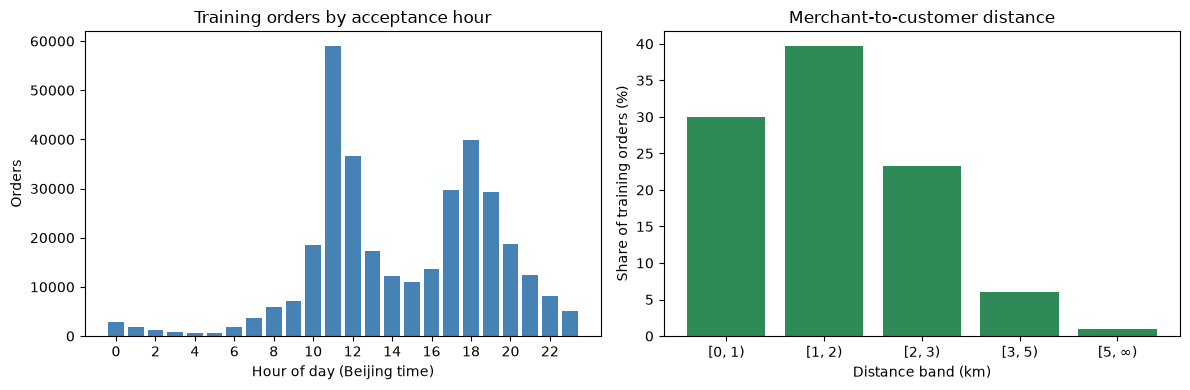

In [22]:
hourly = freq_tables["接单小时"]
distance = freq_tables["商家至顾客距离档"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(hourly.index, hourly["订单数"], color="steelblue")
axes[0].set(
    title="Training orders by acceptance hour",
    xlabel="Hour of day (Beijing time)",
    ylabel="Orders",
    xticks=np.arange(0, 24, 2),
)

axes[1].bar(
    distance.index.astype(str),
    distance["订单占比(%)"],
    color="seagreen",
)
axes[1].set(
    title="Merchant-to-customer distance",
    xlabel="Distance band (km)",
    ylabel="Share of training orders (%)",
)

fig.tight_layout()
plt.show()


图中分别展示接单小时的订单数和距离档的订单占比。时段与距离组的样本量差异较大，后续比较晚到率和错误率时需同时报告各组订单数。


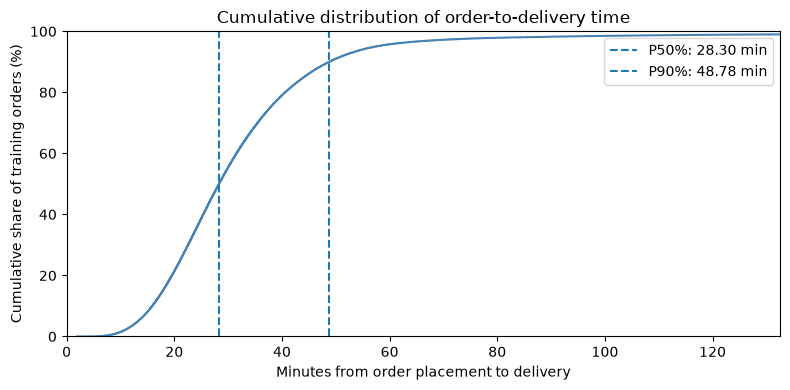

In [23]:
# 累计比例使用全部有效耗时；P99 仅限制横轴显示范围。
duration = train_numeric["order_to_arrive_min"].dropna()
sorted_minutes = duration.sort_values().to_numpy()

cumulative_pct = np.arange(1, len(sorted_minutes) + 1) / len(sorted_minutes) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.step(sorted_minutes, cumulative_pct, where="post", color="steelblue")

for q in [0.50, 0.90]:
    minutes = duration.quantile(q)
    ax.axvline(minutes, linestyle="--", label=f"P{q:.0%}: {minutes:.2f} min")

ax.set_xlim(0, duration.quantile(0.99))
ax.set_ylim(0, 100)
ax.set(
    title="Cumulative distribution of order-to-delivery time",
    xlabel="Minutes from order placement to delivery",
    ylabel="Cumulative share of training orders (%)",
)
ax.legend()

fig.tight_layout()
plt.show()


训练集中，下单至送达耗时的中位数为 28.30 分钟，P90 为 48.78 分钟。经验累计分布使用全部有效耗时计算，横轴仅显示至 P99。


In [24]:
# 按训练订单汇总组内晚到率，保留缺失类别。
orders = df_train[["y_0", "y_8"]].copy()

orders["hour"] = category_columns["接单小时"]
orders["distance_band"] = category_columns["商家至顾客距离档"]

orders["booking"] = df_train["is_prebook"].map({
    0: "On-demand",
    1: "Prebooked",
})


def summarize_late(by):
    table = orders.groupby(by, observed=True, dropna=False).agg(
        orders=("y_0", "size"),
        late=("y_0", "sum"),
        late_8=("y_8", "sum"),
    )

    table["late_pct"] = 100 * table["late"] / table["orders"]
    table["late_8_pct"] = 100 * table["late_8"] / table["orders"]
    return table


late_by_hour = summarize_late("hour")
late_by_distance = summarize_late("distance_band")
late_by_booking = summarize_late("booking")

late_by_distance_booking = summarize_late(["distance_band", "booking"])

overall_late_pct = orders["y_0"].mean() * 100

display(late_by_hour.loc[[9, 11, 12, 18]].round(2))
display(late_by_distance.round(2))
display(late_by_booking.round(2))
display(late_by_distance_booking.round(2))


,orders,late,late_8,late_pct,late_8_pct
hour,,,,,
9,7138,638,74,8.94,1.04
11,59032,10862,1204,18.40,2.04
12,36529,4654,485,12.74,1.33
18,39945,7588,1058,19.00,2.65


,orders,late,late_8,late_pct,late_8_pct
distance_band,,,,,
"[0, 1)",101439,8529,881,8.41,0.87
"[1, 2)",134357,21094,2078,15.70,1.55
"[2, 3)",78582,15605,1976,19.86,2.51
"[3, 5)",20606,4314,1028,20.94,4.99
"[5, ∞)",3268,680,275,20.81,8.41


,orders,late,late_8,late_pct,late_8_pct
booking,,,,,
On-demand,324830,47457,5810,14.61,1.79
Prebooked,13422,2765,428,20.60,3.19


orders   late  late_8  late_pct  late_8_pct
distance_band booking                                               
[0, 1)        On-demand   98657   8024     827      8.13        0.84
              Prebooked    2782    505      54     18.15        1.94
[1, 2)        On-demand  129105  20054    1961     15.53        1.52
              Prebooked    5252   1040     117     19.80        2.23
[2, 3)        On-demand   74802  14849    1872     19.85        2.50
              Prebooked    3780    756     104     20.00        2.75
[3, 5)        On-demand   19333   3984     941     20.61        4.87
              Prebooked    1273    330      87     25.92        6.83
[5, ∞)        On-demand    2933    546     209     18.62        7.13
              Prebooked     335    134      66     40.00       19.70

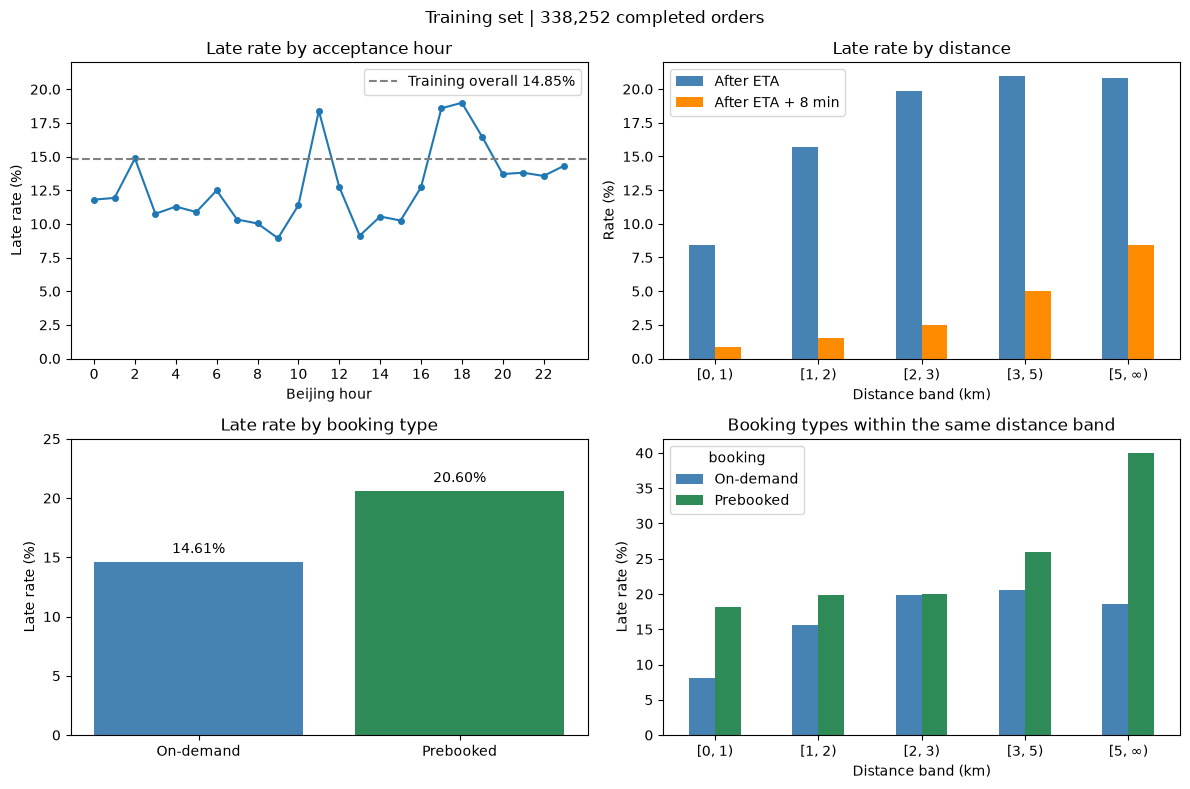

In [25]:
distance_plot = late_by_distance[["late_pct", "late_8_pct"]].rename(
    columns={"late_pct": "After ETA", "late_8_pct": "After ETA + 8 min"}
)

booking_order = ["On-demand", "Prebooked"]

within_distance = (
    late_by_distance_booking["late_pct"]
    .unstack("booking")
    .reindex(index=late_by_distance.index, columns=booking_order)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
ax.plot(late_by_hour.index, late_by_hour["late_pct"], marker="o", markersize=4)
ax.axhline(
    overall_late_pct, color="gray", linestyle="--",
    label=f"Training overall {overall_late_pct:.2f}%"
)
ax.set(title="Late rate by acceptance hour", xlabel="Beijing hour",
       ylabel="Late rate (%)", xticks=np.arange(0, 24, 2), ylim=(0, 22))
ax.legend()

distance_plot.plot.bar(ax=axes[0, 1], rot=0, color=["steelblue", "darkorange"])
axes[0, 1].set(title="Late rate by distance", xlabel="Distance band (km)",
               ylabel="Rate (%)")

ax = axes[1, 0]
bars = ax.bar(booking_order, late_by_booking.loc[booking_order, "late_pct"],
              color=["steelblue", "seagreen"])
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set(title="Late rate by booking type", ylabel="Late rate (%)", ylim=(0, 25))

within_distance.plot.bar(ax=axes[1, 1], rot=0, color=["steelblue", "seagreen"])
axes[1, 1].set(title="Booking types within the same distance band",
               xlabel="Distance band (km)", ylabel="Late rate (%)")

fig.suptitle(f"Training set | {len(orders):,} completed orders")
fig.tight_layout()
plt.show()


训练集 11 点和 18 点接单订单的 `y_0` 晚到率分别为 18.40% 和 19.00%，均高于总体的 14.85%。11 点接单订单贡献了全部晚到订单的 21.63%；这一比例以全部晚到订单为分母，与该时段的组内晚到率不同。

`y_0` 晚到率在 [3, 5) 公里组最高，为 20.94%；`y_8` 正例率随距离档上升，从 0.87% 增至 8.41%。[1, 2) 公里组有 21,094 笔晚到，占全部晚到订单的 42.00%，其较大订单基数也影响晚到笔数。

预约与非预约订单的 `y_0` 晚到率分别为 20.60% 和 14.61%，相差 5.99 个百分点。各距离档内预约组的晚到率均较高，但差异幅度不一；5 公里及以上的预约组仅有 335 笔。


In [26]:
# 比较五个独立配送阶段；总耗时不作为额外阶段重复计入。
stage_names = {
    "order_to_push_min": "Order → push",
    "push_to_dispatch_min": "Push → dispatch",
    "dispatch_to_grab_min": "Dispatch → accept",
    "grab_to_fetch_min": "Accept → pickup",
    "fetch_to_arrive_min": "Pickup → delivery",
}
segments = list(stage_names)

stage_data = df_train[["y_0", "y_8", "is_prebook"] + segments]

cohorts = {
    "All orders": stage_data,
    "Non-prebooked": stage_data.loc[stage_data["is_prebook"].eq(0)],
    "Prebooked": stage_data.loc[stage_data["is_prebook"].eq(1)],
}


def summarize_stages(frame):
    summary = frame[segments].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    ).T

    summary["valid_n"] = summary["count"].astype(int)
    summary["missing_n"] = len(frame) - summary["valid_n"]

    return summary[
        ["valid_n", "missing_n", "mean", "25%", "50%", "75%", "90%"]
    ]


def compare_stages(label):
    summaries = {}

    for name, frame in cohorts.items():
        summaries[name] = pd.concat({
            0: summarize_stages(frame.loc[frame[label].eq(0)]),
            1: summarize_stages(frame.loc[frame[label].eq(1)]),
        }, names=["status", "stage"])

    # 正值表示晚到组的阶段中位耗时更长。
    gaps = pd.DataFrame({
        name: table.loc[1, "50%"] - table.loc[0, "50%"]
        for name, table in summaries.items()
    }).rename(index=stage_names)

    return summaries, gaps


stage_stats, median_gap = compare_stages("y_0")

display(stage_stats["All orders"].rename(index=stage_names, level="stage").round(2))
display(median_gap.round(2))


valid_n  missing_n   mean    25%    50%    75%  \
status stage                                                               
0      Order → push        288030          0   2.15   0.12   0.20   0.38   
       Push → dispatch     288029          1   6.52   0.35   1.47   4.95   
       Dispatch → accept   288029          1   0.38   0.12   0.18   0.32   
       Accept → pickup     288030          0   9.50   5.42   8.55  12.55   
       Pickup → delivery   288030          0  13.88   7.60  12.18  18.50   
1      Order → push         50222          0   4.56   0.13   0.22   0.52   
       Push → dispatch      50222          0   9.32   0.53   3.38   6.48   
       Dispatch → accept    50222          0   0.72   0.12   0.20   0.38   
       Accept → pickup      50222          0  14.27   7.92  12.87  19.03   
       Pickup → delivery    50222          0  24.01  15.97  23.37  30.92   

                            90%  
status stage                     
0      Order → push        2.35  
       Push → dispatch     8.27  
       Dispatch → accept   0.65  
       Accept → pickup    16.78  
       Pickup → delivery  25.30  
1      Order → push        4.57  
       Push → dispatch    10.88  
       Dispatch → accept   1.08  
       Accept → pickup    25.30  
       Pickup → delivery  38.40

,All orders,Non-prebooked,Prebooked
stage,,,
Order → push,0.02,0.02,0.02
Push → dispatch,1.92,1.82,-3.78
Dispatch → accept,0.02,0.02,0.00
Accept → pickup,4.32,4.18,6.33
Pickup → delivery,11.18,11.28,5.23


下表为训练集中晚到组减去准时组的阶段耗时中位数差，单位为分钟；正值表示晚到组的中位耗时更长。

| 阶段 | 全部订单 | 非预约 | 预约 |
|---|---:|---:|---:|
| 下单 → 推送 | +0.02 | +0.02 | +0.02 |
| 推送 → 派单 | +1.92 | +1.82 | -3.78 |
| 派单 → 接单 | +0.02 | +0.02 | 0.00 |
| 接单 → 取餐 | +4.32 | +4.18 | +6.33 |
| 取餐 → 送达 | +11.18 | +11.28 | +5.23 |


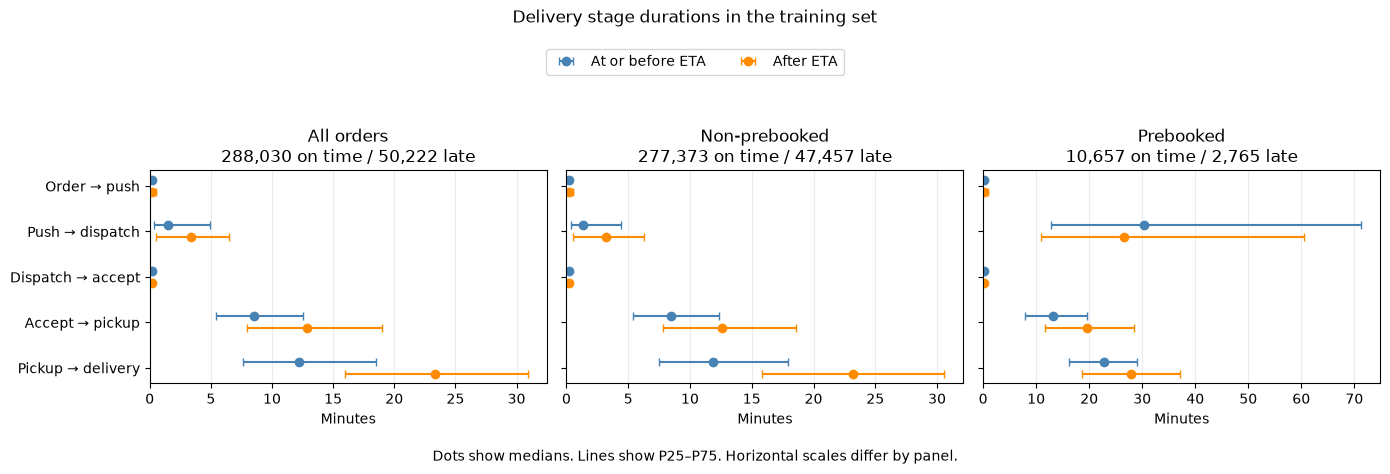

In [27]:
# 点为中位数，误差线为 P25–P75；各面板横轴范围独立。
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), sharey=True)
y_pos = np.arange(len(segments))

for ax, (name, summary) in zip(axes, stage_stats.items()):
    for status, offset, color, caption in [
        (0, -0.13, "steelblue", "At or before ETA"),
        (1,  0.13, "darkorange", "After ETA"),
    ]:
        table = summary.loc[status].reindex(segments)
        median = table["50%"]

        widths = np.vstack([
            median - table["25%"],
            table["75%"] - median,
        ])

        ax.errorbar(
            median, y_pos + offset,
            xerr=widths, fmt="o", color=color, capsize=3, label=caption,
        )

    on_time_n = cohorts[name]["y_0"].eq(0).sum()
    late_n = cohorts[name]["y_0"].eq(1).sum()
    ax.set_title(f"{name}\n{on_time_n:,} on time / {late_n:,} late")
    ax.set_xlabel("Minutes")
    ax.set_xlim(left=0)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_yticks(y_pos, list(stage_names.values()))
axes[0].invert_yaxis()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.91), ncol=2)
fig.suptitle("Delivery stage durations in the training set")
fig.text(
    0.5, 0.02,
    "Dots show medians. Lines show P25–P75. Horizontal scales differ by panel.",
    ha="center",
)
fig.tight_layout(rect=[0, 0.06, 1, 0.83])
plt.show()


全部订单中，晚到组与准时组的中位耗时差主要出现在取餐至送达阶段，为 11.18 分钟；接单至取餐阶段相差 4.32 分钟。非预约订单占训练集约 96%，其阶段差异与总体结果接近。

预约订单的最大正向差异出现在接单至取餐阶段，为 6.33 分钟。预约订单推送至派单的中位耗时较长，但晚到组比准时组短 3.78 分钟。阶段耗时水平与晚到、准时两组的耗时差分别描述过程时长和组间差异；本节据此定位耗时差异集中的环节。延迟机制的识别还需要履约过程数据和专门的因果分析设计。图中各面板的横轴尺度不同，应按分钟数比较。


## 5. 特征工程与可得性核查

特征选择依据是业务相关性、接单时点的字段定义和可解释性：用少量变量覆盖接单前等待、取餐与送餐的空间跨度，以及时段、订单类型和区域差异。本次实验评价这组变量的预测表现；单项特征的增益和替代方案需通过消融实验比较。

输入包含 4 个连续特征、4 个类别特征和 4 个数值缺失标记。填补、标准化和类别编码仅在训练集拟合，验证集和测试集复用同一转换器。

| 特征 | 选择依据与拟表达的信息 | 信息范围 |
|---|---|---|
| 商家至顾客距离 | 用近似地理距离描述送餐路段的空间跨度，是配送工作量的简单代理 | 几何距离反映空间跨度，实际路线和交通状况需要路网及交通数据描述 |
| 骑手接单位置至商家距离 | 描述接单后前往取餐点的空间跨度，补充送餐距离之外的信息 | 任务量和实际取餐耗时需要结合骑手任务及履约记录分析 |
| `dispatch_to_grab_min` | 描述本次派单至接单的响应间隔，反映接单前已发生的等待 | 间隔用于预测关联分析，等待原因和骑手效率需要更完整的调度过程记录 |
| `push_to_grab_min` | 描述订单进入调度至接单的累计等待，覆盖本次派单之前的过程 | 与派单至接单间隔部分重叠，两者分别保留累计等待和末段响应信息 |
| `grab_hour` | 用接单小时区分午餐、晚餐及非高峰时段的风险模式 | 时段用作运营情境的代理，需求、运力和拥堵程度需要直接观测 |
| `order_hour` | 保留下单时段，补充预约或跨时段接单订单的信息 | 与接单小时、预约类型可能相关，完整等待时长由事件时间戳计算 |
| `is_prebook` | 区分预约与即时订单，保留两类订单的时间安排差异 | 用于比较订单类型的预测关联，预约的因果效应需要专门的识别设计 |
| `da_id` | 允许不同运营区域具有不同的基准风险模式 | 区域编号作为类别标识，各区域的关联分别估计 |
| 数值缺失标记 | 区分真实观测值与后续填补值，保留记录缺失状态 | 训练缺失很少，部分标记恒定；其作用是显式记录填补状态 |

小时、预约类型和区域按类别编码，使 Logistic Regression 分别估计各类别的关联。订单、骑手和商户 ID 未作为输入，以控制当前模型复杂度，减少依赖个体标识进行记忆的机会。历史行为特征需要按预测时点组织过去记录，并另行评价其增益。

[数据说明论文](<../data/Meituan-INFORMS-TSL-Research-Challenge/Wang-etal-2025_Meituan_Operational-Level On-Demand Food Delivery Data for the 2025 INFORMS TSL Data-Driven Research Challenge.pdf>)第 7–8 页支持事件时间和接单位置的定义：`grab_lat`、`grab_lng` 为接单时位置；派单和进入调度的耗时均截止于 `grab_time`。本分析据此构造接单时特征，部署时还需通过在线读取日志和历史快照核验字段可得性。

`estimate_arrived_time` 用于标签和回溯提前量，其与接单时可见 ETA 版本的一致性需要历史记录核验。`fetch_time`、`arrive_time` 及接单后的阶段耗时仅用于标签构造或事后分析。

### 日历构成与特征设定

本次保持原有特征及模型参数，通过开发集分组让训练和验证都包含周六，集中评价验证方案。接单日周末变量未加入模型。

原始 `is_weekend` 按项目数据字典记录创建日口径，接单日周末标记则由 `grab_time` 的北京时间日期计算。本次使用的 568,076 笔订单中，两种口径在 704 笔订单上不同。本分析按周六、周日定义周末；法定节假日和调休需要另行匹配日历。当前模型未使用该列，日历特征的独立增益留待后续实验评价。


In [28]:
# 按接单时点的字段定义构造特征；距离为公里，耗时为分钟。
numeric_features = [
    "merchant_to_customer_km",
    "rider_to_merchant_km",
    "dispatch_to_grab_min",
    "push_to_grab_min",
]

categorical_features = ["grab_hour", "order_hour", "is_prebook", "da_id"]

missing_flags = [f"{col}_missing" for col in numeric_features]
feature_cols = numeric_features + categorical_features + missing_flags


def build_features(frame):
    # 显式选列，排除 ETA、实际送达及接单后的阶段耗时。
    X = frame[[
        "merchant_to_customer_km", "rider_to_merchant_km",
        "dispatch_to_grab_min", "is_prebook", "da_id",
    ]].copy()

    X["grab_hour"] = frame["grab_time_dt"].dt.hour
    X["order_hour"] = frame["platform_order_time_dt"].dt.hour

    # 负耗时保留为缺失，缺失标记在填补前生成。
    minutes = (frame["grab_time"] - frame["order_push_time"]) / 60
    X["push_to_grab_min"] = minutes.where(minutes.ge(0))

    for col in numeric_features:
        X[f"{col}_missing"] = X[col].isna().astype("int8")

    for col in categorical_features:
        X[col] = X[col].astype("string").fillna("Missing").astype(str)

    # 固定列顺序以保证三个数据集一致。
    return X[feature_cols]


X_train = build_features(df_train)
X_val = build_features(df_val)
X_test = build_features(df_test)

target_cols = ["y_0", "y_8"]
y_train = df_train[target_cols].copy()
y_val = df_val[target_cols].copy()
y_test = df_test[target_cols].copy()

for name, X, y in [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test),
]:
    print(name, "X:", X.shape, "y:", y.shape, "索引对齐:", X.index.equals(y.index))

display(X_train[numeric_features].isna().sum().to_frame("训练集缺失数"))


train X: (338252, 12) y: (338252, 2) 索引对齐: True
val X: (84756, 12) y: (84756, 2) 索引对齐: True
test X: (145068, 12) y: (145068, 2) 索引对齐: True


,训练集缺失数
merchant_to_customer_km,0
rider_to_merchant_km,0
dispatch_to_grab_min,1
push_to_grab_min,0


### 极端耗时核查


In [29]:
duration_features = ["dispatch_to_grab_min", "push_to_grab_min"]
audit_feature_sets = {"Train": X_train, "Validation": X_val, "Test": X_test}
duration_audit_tables = {}

for split, features in audit_feature_sets.items():
    table = features[duration_features].describe(percentiles=[0.99, 0.995]).T
    table["missing"] = features[duration_features].isna().sum()
    duration_audit_tables[split] = table[["count", "missing", "99%", "99.5%", "max"]]

duration_audit_summary = pd.concat(
    duration_audit_tables, names=["split", "feature"]
)
display(duration_audit_summary.round(4))

# 仅核查已进入训练、验证或测试的订单，保留原始事件时间。
audit_features = pd.concat(audit_feature_sets, names=["split", "row_index"])
audit_record_cols = [
    "order_id", "is_prebook", "platform_order_time_dt", "order_push_time_dt",
    "dispatch_time_dt", "grab_time_dt", "fetch_time_dt", "arrive_time_dt",
]
extreme_duration_tables = {}
for feature in duration_features:
    largest = audit_features[feature].nlargest(3)
    records = df_clean.loc[largest.index.get_level_values("row_index"), audit_record_cols].copy()
    records.insert(0, "split", largest.index.get_level_values("split"))
    records["duration_min"] = largest.to_numpy()
    extreme_duration_tables[feature] = records

extreme_duration_records = pd.concat(
    extreme_duration_tables, names=["feature", "row_index"]
)
display(extreme_duration_records)


count  missing      99%     99.5%  \
split      feature                                                      
Train      dispatch_to_grab_min  338251.0        1   4.8000    7.1000   
           push_to_grab_min      338252.0        0  69.4000  154.0206   
Validation dispatch_to_grab_min   84756.0        0   4.8000    6.8167   
           push_to_grab_min       84756.0        0  73.8500  170.7908   
Test       dispatch_to_grab_min  145068.0        0   5.0333    7.3222   
           push_to_grab_min      145068.0        0  57.9943  124.6547   

                                        max  
split      feature                           
Train      dispatch_to_grab_min    319.7667  
           push_to_grab_min      10293.1167  
Validation dispatch_to_grab_min     65.1667  
           push_to_grab_min       8634.2000  
Test       dispatch_to_grab_min    111.3167  
           push_to_grab_min       6110.1500

split  order_id  is_prebook  \
feature              row_index                                     
dispatch_to_grab_min 259043          Train    242141           1   
                     233025          Train    219102           1   
                     238375           Test    223856           1   
push_to_grab_min     24716           Train     24526           1   
                     391494          Train    356027           1   
                     285121     Validation    265059           1   

                                  platform_order_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-17 23:46:38+08:00   
                     233025    2022-10-18 14:12:53+08:00   
                     238375    2022-10-23 16:37:42+08:00   
push_to_grab_min     24716     2022-10-15 07:33:56+08:00   
                     391494    2022-10-15 09:36:05+08:00   
                     285121    2022-10-12 11:18:07+08:00   

                                      order_push_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-17 23:46:53+08:00   
                     233025    2022-10-18 14:12:59+08:00   
                     238375    2022-10-23 16:38:02+08:00   
push_to_grab_min     24716     2022-10-15 07:34:17+08:00   
                     391494    2022-10-15 09:36:17+08:00   
                     285121    2022-10-12 11:18:19+08:00   

                                        dispatch_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 00:53:27+08:00   
                     233025    2022-10-18 15:22:59+08:00   
                     238375    2022-10-23 16:38:02+08:00   
push_to_grab_min     24716     2022-10-22 11:07:02+08:00   
                     391494    2022-10-22 10:54:32+08:00   
                     285121    2022-10-18 11:11:51+08:00   

                                            grab_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 06:13:13+08:00   
                     233025    2022-10-18 17:24:15+08:00   
                     238375    2022-10-23 18:29:21+08:00   
push_to_grab_min     24716     2022-10-22 11:07:24+08:00   
                     391494    2022-10-22 10:58:54+08:00   
                     285121    2022-10-18 11:12:31+08:00   

                                           fetch_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 10:49:04+08:00   
                     233025    2022-10-18 17:24:46+08:00   
                     238375    2022-10-23 18:31:19+08:00   
push_to_grab_min     24716     2022-10-22 11:15:18+08:00   
                     391494    2022-10-22 11:12:15+08:00   
                     285121    2022-10-18 11:23:07+08:00   

                                          arrive_time_dt  duration_min  
feature              row_index                                          
dispatch_to_grab_min 259043    2022-10-18 11:14:25+08:00    319.766667  
                     233025    2022-10-18 18:15:11+08:00    121.266667  
                     238375    2022-10-23 18:46:46+08:00    111.316667  
push_to_grab_min     24716     2022-10-22 11:50:25+08:00  10293.116667  
                     391494    2022-10-22 11:43:05+08:00  10162.616667  
                     285121    2022-10-18 11:50:03+08:00   8634.200000

训练集派单至接单耗时的 P99 为 4.80 分钟，P99.5 为 7.10 分钟，最大值为 319.77 分钟；推送至接单耗时的对应值为 69.40、154.02 和 10,293.12 分钟。后者最大值对应训练订单 24526：推送时间为 10 月 15 日 07:34:17，接单时间为 10 月 22 日 11:07:24（北京时间）。验证集推送至接单的最大值为 8,634.20 分钟。

所列极端记录均为预约订单，部分存在跨日的长时间间隔，所检查的事件顺序一致。现有核查覆盖时间顺序，区分长等待、重入调度和记录问题还需要业务过程记录。本分析保留这些极端正值，后续可依据业务核验结果制定纠错规则。


In [30]:
# 填补、标准化和类别编码仅在训练集拟合。
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),

    # 未见类别编码为全零；缺失标记直接传递。
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),

    ("flag", "passthrough", missing_flags),
])

X_train_ready = preprocessor.fit_transform(X_train)

# 验证集只转换，不重新拟合预处理参数。
X_val_ready = preprocessor.transform(X_val)

imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]
train_medians = pd.Series(
    imputer.statistics_, index=numeric_features, name="训练集中位数",
)
display(train_medians.round(4).to_frame())

encoder = preprocessor.named_transformers_["category"]
category_sizes = pd.Series(
    [len(values) for values in encoder.categories_],
    index=categorical_features,
    name="训练集类别数",
)
display(category_sizes.to_frame())

print("转换后训练集:", X_train_ready.shape)
print("转换后验证集:", X_val_ready.shape)


转换后训练集: (338252, 81)
转换后验证集: (84756, 81)


,训练集中位数
merchant_to_customer_km,1.4669
rider_to_merchant_km,0.4676
dispatch_to_grab_min,0.1833
push_to_grab_min,2.2167


,训练集类别数
grab_hour,24
order_hour,24
is_prebook,2
da_id,23


## 6. 基准与模型比较

随机基准使用固定随机种子，距离规则按商家至顾客距离排序。Logistic Regression 与 XGBoost 使用相同预处理特征，均只在训练集拟合；模型参数和随机种子沿用上一版设定，本轮调整集中在数据划分与验证方式。主分析先在六个历史日期的分组验证集中比较 `y_0` 的 AP 和 ROC-AUC，再检验指定监控容量下的结果。


In [31]:
# 先按订单 ID 排序，再生成固定种子的随机基准分数。
val_baselines = df_val[["order_id", "y_0", "y_8"]].sort_values("order_id").copy()

rng = np.random.default_rng(RANDOM_SEED)
val_baselines["random_score"] = rng.random(len(val_baselines))

# 距离缺失用训练中位数填补，按原始索引对齐。
val_baselines["distance_score_km"] = X_val["merchant_to_customer_km"].fillna(
    train_medians["merchant_to_customer_km"]
)

# 两个标签复用基准分数，分别评估。
rows = []
for target in target_cols:
    truth = val_baselines[target]

    for method, score_col in [
        ("Random", "random_score"),
        ("Distance", "distance_score_km"),
    ]:
        scores = val_baselines[score_col]

        rows.append({
            "label": target,
            "method": method,
            "positive_rate": truth.mean(),
            "AP": average_precision_score(truth, scores),
            "ROC-AUC": roc_auc_score(truth, scores),
        })

baseline_metrics = pd.DataFrame(rows)
display(val_baselines.head(3).round(4))
display(baseline_metrics.round(5))


,order_id,y_0,y_8,random_score,distance_score_km
1,1,0,0,0.7740,1.0016
9,9,0,0,0.4389,0.9344
19,19,0,0,0.8586,0.9602


,label,method,positive_rate,AP,ROC-AUC
0,y_0,Random,0.15408,0.15312,0.49931
1,y_0,Distance,0.15408,0.19647,0.60700
2,y_8,Random,0.01972,0.02004,0.49906
3,y_8,Distance,0.01972,0.04262,0.65925


In [32]:
# 以 y_0 拟合固定参数的 Logistic Regression。
target = "y_0"

lr_model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)

lr_model.fit(X_train_ready, y_train[target])

print("类别顺序:", lr_model.classes_)
print("实际迭代次数:", lr_model.n_iter_[0])

# 保存正类分数并恢复原始索引，便于与其他方法对齐。
lr_val_score = pd.Series(
    lr_model.predict_proba(X_val_ready)[:, 1],
    index=X_val.index,
    name="logistic_score",
)

print("验证分数条数:", len(lr_val_score))
display(lr_val_score.head().round(5))


类别顺序: [0 1]
实际迭代次数: 48
验证分数条数: 84756


1     0.07859
9     0.08876
19    0.05400
20    0.09760
31    0.09400
Name: logistic_score, dtype: float64

In [33]:
# 使用 float32 稠密输入，显式保留零值，避免与缺失值混淆。
X_train_xgb = X_train_ready.astype(np.float32).toarray()
X_val_xgb = X_val_ready.astype(np.float32).toarray()

xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    tree_method="hist",
    random_state=RANDOM_SEED,
    n_jobs=4,
)

xgb_model.fit(X_train_xgb, y_train[target])

xgb_val_score = pd.Series(
    xgb_model.predict_proba(X_val_xgb)[:, 1],
    index=X_val.index,
    name="xgboost_score",
)

print("训练矩阵:", X_train_xgb.shape)
print("验证矩阵:", X_val_xgb.shape)
print("实际训练轮数:", xgb_model.get_booster().num_boosted_rounds())
display(xgb_val_score.head().round(5))


训练矩阵: (338252, 81)
验证矩阵: (84756, 81)
实际训练轮数: 200


1     0.14640
9     0.08463
19    0.09723
20    0.11844
31    0.09875
Name: xgboost_score, dtype: float32

In [34]:
# 按原始行索引合并验证分数，检查完整性后比较排序指标。
validation_scores = val_baselines.copy()
validation_scores["logistic_score"] = lr_val_score
validation_scores["xgboost_score"] = xgb_val_score

score_columns = {
    "Random": "random_score",
    "Distance": "distance_score_km",
    "Logistic Regression": "logistic_score",
    "XGBoost": "xgboost_score",
}

assert len(validation_scores) == len(X_val)
assert validation_scores[list(score_columns.values())].notna().all().all()

truth = validation_scores[target]

comparison_rows = []
for method, col in score_columns.items():
    scores = validation_scores[col]
    comparison_rows.append({
        "method": method,
        "AP": average_precision_score(truth, scores),
        "ROC-AUC": roc_auc_score(truth, scores),
    })

model_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("AP", ascending=False, ignore_index=True)
)

print(f"验证集正例率: {truth.mean():.2%}")
display(model_comparison.round(5))


验证集正例率: 15.41%


,method,AP,ROC-AUC
0,XGBoost,0.28464,0.69041
1,Logistic Regression,0.25975,0.67077
2,Distance,0.19647,0.60700
3,Random,0.15312,0.49931


分组验证集上，XGBoost 的 AP 为 0.28464，高于 Logistic Regression 的 0.25975、距离规则的 0.19647 和随机基准的 0.15312。随机基准的 AP 接近该集正例率 15.41%。AP 汇总不同召回水平下的排序表现。

XGBoost 的 ROC-AUC 为 0.69041，表示随机抽取一笔晚到订单和一笔准时订单时，模型将晚到订单排在前面的比例约为 69.04%，同分计半。这是相同历史期的留组验证结果；后续固定阈值，并在更晚的整日测试数据上评价。


## 7. 监控容量与阈值选择

验证集先按分数降序选取前 `ceil(n × q)` 笔，比较 5%、10%、20% 的目标监控比例；同分按订单 ID 排序。精确率为命中数除以监控数，覆盖率（Recall）为命中数除以实际晚到数。

随后在验证集上选择可用于逐单判断的分数阈值并固定，在测试集检验其实际工作量。


In [35]:
# 按分数选取前 ceil(n × q) 笔；同分按订单 ID 排序。
from math import ceil

capacity_target = "y_0"
capacities = [5, 10, 20]

n_orders = len(validation_scores)
n_late = int(validation_scores[capacity_target].sum())

capacity_rows = []

for method, score_col in score_columns.items():
    ranked = validation_scores.sort_values(
        [score_col, "order_id"],
        ascending=[False, True],
    )

    for capacity in capacities:
        k = ceil(n_orders * capacity / 100)

        selected = ranked.head(k)

        hits = int(selected[capacity_target].sum())

        capacity_rows.append({
            "capacity_pct": capacity,
            "method": method,
            "monitored": k,
            "hits": hits,
            "precision_pct": 100 * hits / k,
            "coverage_pct": 100 * hits / n_late,
        })

validation_topq = (
    pd.DataFrame(capacity_rows)
    .sort_values(["capacity_pct", "hits"], ascending=[True, False], ignore_index=True)
)

print(f"验证集订单 {n_orders:,} 笔，其中晚到 {n_late:,} 笔")
display(validation_topq.round(2))


验证集订单 84,756 笔，其中晚到 13,059 笔


,capacity_pct,method,monitored,hits,precision_pct,coverage_pct
0,5,XGBoost,4238,1585,37.40,12.14
1,5,Logistic Regression,4238,1411,33.29,10.80
2,5,Distance,4238,859,20.27,6.58
3,5,Random,4238,625,14.75,4.79
4,10,XGBoost,8476,2756,32.52,21.10
5,10,Logistic Regression,8476,2494,29.42,19.10
6,10,Distance,8476,1829,21.58,14.01
7,10,Random,8476,1251,14.76,9.58
8,20,XGBoost,16952,4832,28.50,37.00
9,20,Logistic Regression,16952,4528,26.71,34.67


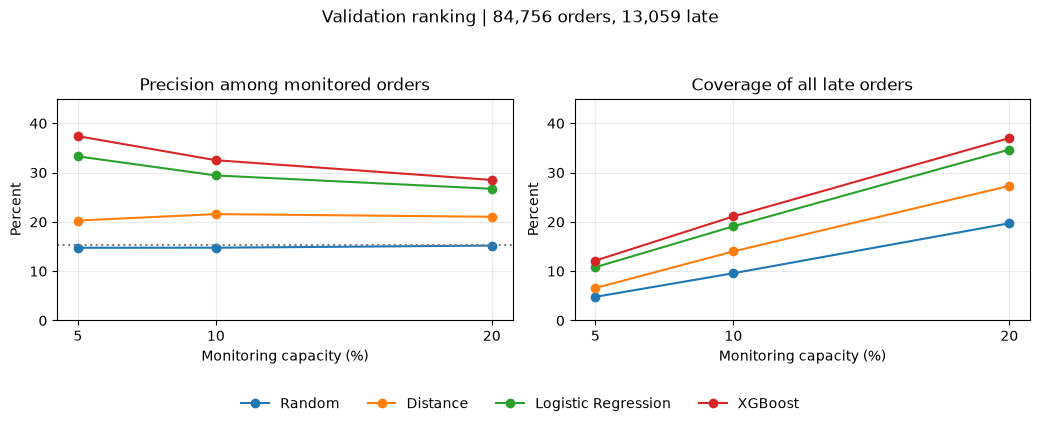

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

for method in score_columns:
    points = validation_topq.loc[
        validation_topq["method"].eq(method)
    ].sort_values("capacity_pct")

    axes[0].plot(
        points["capacity_pct"], points["precision_pct"], marker="o", label=method
    )
    axes[1].plot(
        points["capacity_pct"], points["coverage_pct"], marker="o", label=method
    )

for ax, title in zip(axes, [
    "Precision among monitored orders",
    "Coverage of all late orders",
]):
    ax.set(
        title=title, xlabel="Monitoring capacity (%)",
        ylabel="Percent", xticks=capacities, ylim=(0, 45),
    )
    ax.grid(alpha=0.25)

axes[0].axhline(100 * n_late / n_orders, color="gray", linestyle=":")

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"Validation ranking | {n_orders:,} orders, {n_late:,} late")
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.10, 1, 0.93])
plt.show()


验证集按排名监控前 10% 的订单时，XGBoost 的精确率为 32.52%，覆盖率为 21.10%；随机基准覆盖率为 9.58%。将 XGBoost 的监控比例增至 20%，需多监控 8,476 笔订单，多命中 2,076 笔，覆盖率增至 37.00%，精确率降至 28.50%。扩大监控范围提高了晚到识别量，同时降低了单位监控量的命中比例。


In [37]:
# 同分订单整体纳入，选择验证监控量最接近目标的阈值。
def choose_threshold(scores, capacity_pct):
    score_counts = scores.value_counts().sort_index(ascending=False)

    monitored_by_threshold = score_counts.cumsum()

    # 加入不预警的候选规则。
    monitored_by_threshold = pd.concat([
        pd.Series([0], index=[np.inf]),
        monitored_by_threshold,
    ])

    # 使用整数尺度比较偏差；同距时取更高阈值，监控量更小。
    gap = (100 * monitored_by_threshold - capacity_pct * len(scores)).abs()

    threshold = gap.idxmin()
    monitored = int(monitored_by_threshold.loc[threshold])
    return float(threshold), monitored


threshold_rows = []

for method, score_col in score_columns.items():
    scores = validation_scores[score_col]
    for capacity in capacities:
        threshold, monitored = choose_threshold(scores, capacity)
        threshold_rows.append({
            "method": method,
            "score_col": score_col,
            "target_pct": capacity,
            "threshold": threshold,
            "val_monitored": monitored,
            "val_actual_pct": 100 * monitored / len(scores),
        })

validation_thresholds = pd.DataFrame(threshold_rows)

display(validation_thresholds.round(6))


,method,score_col,target_pct,threshold,val_monitored,val_actual_pct
0,Random,random_score,5,0.950148,4238,5.000236
1,Random,random_score,10,0.900481,8476,10.000472
2,Random,random_score,20,0.798911,16951,19.999764
3,Distance,distance_score_km,5,3.264033,4238,5.000236
4,Distance,distance_score_km,10,2.811030,8476,10.000472
5,Distance,distance_score_km,20,2.364936,16951,19.999764
6,Logistic Regression,logistic_score,5,0.284565,4238,5.000236
7,Logistic Regression,logistic_score,10,0.241471,8476,10.000472
8,Logistic Regression,logistic_score,20,0.202891,16951,19.999764
9,XGBoost,xgboost_score,5,0.292928,4238,5.000236


阈值仅根据验证集分数确定，使 `score >= threshold` 对应的监控量尽可能接近目标比例。同分订单一起纳入；若两个阈值与目标同样接近，采用监控量较小的阈值。因此，这一规则与严格选取前 k 笔的排名评估可能略有差异。

| 方法 | 5% 目标阈值 | 10% 目标阈值 | 20% 目标阈值 |
|---|---:|---:|---:|
| 随机 | 0.950148 | 0.900481 | 0.798911 |
| 距离 | 3.264033 | 2.811030 | 2.364936 |
| Logistic Regression | 0.284565 | 0.241471 | 0.202891 |
| XGBoost | 0.292928 | 0.257345 | 0.215860 |

表中仅显示六位小数，实际判断使用未舍入阈值。


## 8. 固定阈值的测试集评估

本次实验先完成历史开发集训练与验证，再将模型、预处理参数和阈值固定应用于 10 月 23–24 日。测试期间沿用验证时的模型、预处理器和阈值，实际监控比例由测试分数分布决定。以下分别报告验证目标容量、测试期实际监控率、精确率和覆盖率。


In [38]:
# 测试集复用训练预处理、模型及验证阈值。
X_test_ready = preprocessor.transform(X_test)

X_test_xgb = X_test_ready.astype(np.float32).toarray()

test_scores = df_test[["order_id", "grab_date"]].sort_values("order_id").copy()

test_scores["logistic_score"] = pd.Series(
    lr_model.predict_proba(X_test_ready)[:, 1], index=X_test.index,
)
test_scores["xgboost_score"] = pd.Series(
    xgb_model.predict_proba(X_test_xgb)[:, 1], index=X_test.index,
)

test_scores["distance_score_km"] = X_test["merchant_to_customer_km"].fillna(
    train_medians["merchant_to_customer_km"]
)

# 延续验证集后的随机序列，避免重复使用同一段随机分数。
rng_fixed = np.random.default_rng(RANDOM_SEED)
rng_fixed.random(len(validation_scores))
test_scores["random_score"] = rng_fixed.random(len(test_scores))

test_scores[capacity_target] = y_test[capacity_target]

print(f"测试订单：{len(test_scores):,}")
print(f"实际晚到：{test_scores[capacity_target].sum():,}")


测试订单：145,068
实际晚到：21,922


In [39]:
# 固定验证阈值，分别报告实际工作量、精确率和覆盖率。
def evaluate_thresholds(score_table):
    late = score_table[capacity_target].eq(1)
    total_late = int(late.sum())
    n = len(score_table)
    rows = []

    for rule in validation_thresholds.itertuples(index=False):
        monitored_mask = score_table[rule.score_col].ge(rule.threshold)
        monitored = int(monitored_mask.sum())

        hits = int((monitored_mask & late).sum())

        # 无预警或无正例时，对应比例记为缺失。
        rows.append({
            "target_pct": rule.target_pct,
            "method": rule.method,
            "monitored": monitored,
            "actual_pct": 100 * monitored / n,
            "hits": hits,
            "precision_pct": 100 * hits / monitored if monitored else np.nan,
            "coverage_pct": 100 * hits / total_late if total_late else np.nan,
        })

    return pd.DataFrame(rows).sort_values(
        ["target_pct", "hits"], ascending=[True, False], ignore_index=True,
    )


test_fixed = evaluate_thresholds(test_scores)
display(test_fixed.round(2))


,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
0,5,XGBoost,7230,4.98,2478,34.27,11.30
1,5,Logistic Regression,7281,5.02,2360,32.41,10.77
2,5,Distance,7496,5.17,1628,21.72,7.43
3,5,Random,7249,5.00,1108,15.28,5.05
4,10,XGBoost,14543,10.02,4457,30.65,20.33
5,10,Logistic Regression,14492,9.99,4199,28.97,19.15
6,10,Distance,14274,9.84,3133,21.95,14.29
7,10,Random,14501,10.00,2197,15.15,10.02
8,20,XGBoost,28957,19.96,7737,26.72,35.29
9,20,Logistic Regression,28426,19.59,7270,25.58,33.16


XGBoost 在验证集上按 10% 目标容量确定阈值 0.2573448718。固定应用于测试集后，145,068 笔订单中有 14,543 笔触发预警，其中 4,457 笔实际晚到：

- 实际监控率为 14,543 / 145,068 = **10.02%**，反映测试期的监控工作量。
- 精确率为 4,457 / 14,543 = **30.65%**，反映预警订单中的晚到比例。
- 覆盖率为 4,457 / 21,922 = **20.33%**，反映全部晚到订单中被识别的比例。

同为 10% 验证目标，XGBoost 比 Logistic Regression 多监控 51 笔、多命中 258 笔；比距离规则多监控 269 笔、多命中 1,324 笔。各方法的测试工作量略有差异，应同时比较实际监控率和识别效果。


In [40]:
# 逐日使用同一组阈值；跨日比例需按汇总分子、分母重算。
test_by_day = pd.concat(
    {
        date.strftime("%Y-%m-%d"): evaluate_thresholds(day_scores)
        for date, day_scores in test_scores.groupby("grab_date")
    },
    names=["date"],
).reset_index(level="date").reset_index(drop=True)

display(test_by_day.loc[test_by_day["target_pct"].eq(10)].round(2))


,date,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
4,2022-10-23,10,XGBoost,8098,10.42,2654,32.77,20.56
5,2022-10-23,10,Logistic Regression,7904,10.17,2512,31.78,19.46
6,2022-10-23,10,Distance,7687,9.89,1904,24.77,14.75
7,2022-10-23,10,Random,7643,9.83,1292,16.90,10.01
16,2022-10-24,10,XGBoost,6445,9.57,1803,27.98,20.00
17,2022-10-24,10,Logistic Regression,6588,9.78,1687,25.61,18.72
18,2022-10-24,10,Distance,6587,9.78,1229,18.66,13.63
19,2022-10-24,10,Random,6858,10.18,905,13.20,10.04


同一 XGBoost 阈值在 10 月 23 日和 24 日的实际监控率分别为 10.42% 和 9.57%，命中数分别为 2,654 和 1,803；精确率为 32.77% 和 27.98%，覆盖率为 20.56% 和 20.00%。两天的实际晚到率分别为 16.61% 和 13.38%。两天分别对应周日和周一，指标反映各自日期的综合订单表现。

跨日汇总比例按总分子除以总分母计算。整体监控率接近 10%，逐日工作量仍随分数分布变化。


## 9. `y_8` 敏感性分析

将目标改为超过 ETA 8 分钟后，使用相同特征、训练窗口和 XGBoost 超参数单独拟合模型，并在 `y_8` 验证分数上选择阈值。随机与距离基准复用原分数和阈值，其评价标签改为 `y_8`。两种标签各用对应的 XGBoost 模型评分：`y_0` 对应任何超过 ETA 的晚到，`y_8` 对应超过 ETA 8 分钟的延迟。


In [41]:
# 沿用主模型超参数，为 y_8 独立拟合 XGBoost。
from sklearn.base import clone

target_y8 = "y_8"

xgb_y8_model = clone(xgb_model)

xgb_y8_model.fit(X_train_xgb, y_train[target_y8])

val_scores_y8 = validation_scores[
    ["order_id", target_y8, "random_score", "distance_score_km"]
].copy()

val_scores_y8["xgboost_y8_score"] = pd.Series(
    xgb_y8_model.predict_proba(X_val_xgb)[:, 1],
    index=X_val.index,
)

print(f"训练集 y_8 正例：{y_train[target_y8].sum():,} / {len(y_train):,}")
print(f"验证集 y_8 正例：{val_scores_y8[target_y8].sum():,} / {len(val_scores_y8):,}")
print(f"实际训练轮数：{xgb_y8_model.get_booster().num_boosted_rounds()}")


训练集 y_8 正例：6,238 / 338,252
验证集 y_8 正例：1,671 / 84,756
实际训练轮数：200


In [42]:
# y_8 模型阈值按其验证分数选择；随机与距离规则复用原阈值。
y8_rows = []
y8_score_col = "xgboost_y8_score"

for capacity in capacities:
    threshold, monitored = choose_threshold(
        val_scores_y8[y8_score_col], capacity
    )
    y8_rows.append({
        "method": "XGBoost (y_8)",
        "score_col": y8_score_col,
        "target_pct": capacity,
        "threshold": threshold,
        "val_monitored": monitored,
        "val_actual_pct": 100 * monitored / len(val_scores_y8),
    })

rule_thresholds = validation_thresholds.loc[
    validation_thresholds["method"].isin(["Random", "Distance"])
].copy()

thresholds_y8 = pd.concat(
    [rule_thresholds, pd.DataFrame(y8_rows)], ignore_index=True
)

display(thresholds_y8.round(6))


,method,score_col,target_pct,threshold,val_monitored,val_actual_pct
0,Random,random_score,5,0.950148,4238,5.000236
1,Random,random_score,10,0.900481,8476,10.000472
2,Random,random_score,20,0.798911,16951,19.999764
3,Distance,distance_score_km,5,3.264033,4238,5.000236
4,Distance,distance_score_km,10,2.811030,8476,10.000472
5,Distance,distance_score_km,20,2.364936,16951,19.999764
6,XGBoost (y_8),xgboost_y8_score,5,0.055433,4238,5.000236
7,XGBoost (y_8),xgboost_y8_score,10,0.035493,8476,10.000472
8,XGBoost (y_8),xgboost_y8_score,20,0.022667,16951,19.999764


In [43]:
# 测试标签统一为 y_8；保留各方法的实际监控量。
test_scores_y8 = test_scores[
    ["order_id", "grab_date", "random_score", "distance_score_km"]
].copy()

test_scores_y8["xgboost_y8_score"] = pd.Series(
    xgb_y8_model.predict_proba(X_test_xgb)[:, 1],
    index=X_test.index,
)
test_scores_y8[target_y8] = y_test[target_y8]


def evaluate_fixed_rules(score_table, rules, label_col):
    late = score_table[label_col].eq(1)
    n_orders = len(score_table)
    n_late = int(late.sum())
    rows = []

    for rule in rules.itertuples(index=False):
        monitored_mask = score_table[rule.score_col].ge(rule.threshold)
        monitored = int(monitored_mask.sum())

        hits = int((monitored_mask & late).sum())

        rows.append({
            "target_pct": rule.target_pct,
            "method": rule.method,
            "monitored": monitored,
            "actual_pct": 100 * monitored / n_orders,
            "hits": hits,
            "precision_pct": 100 * hits / monitored if monitored else np.nan,
            "coverage_pct": 100 * hits / n_late if n_late else np.nan,
        })

    return pd.DataFrame(rows).sort_values(
        ["target_pct", "hits"],
        ascending=[True, False],
        ignore_index=True,
    )


test_fixed_y8 = evaluate_fixed_rules(test_scores_y8, thresholds_y8, target_y8)
print(f"测试集 y_8 正例：{test_scores_y8[target_y8].sum():,} / {len(test_scores_y8):,}")
display(test_fixed_y8.round(2))


测试集 y_8 正例：2,963 / 145,068


,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
0,5,XGBoost (y_8),7422,5.12,1060,14.28,35.77
1,5,Distance,7496,5.17,579,7.72,19.54
2,5,Random,7249,5.00,153,2.11,5.16
3,10,XGBoost (y_8),15012,10.35,1420,9.46,47.92
4,10,Distance,14274,9.84,836,5.86,28.21
5,10,Random,14501,10.00,305,2.10,10.29
6,20,XGBoost (y_8),29481,20.32,1828,6.20,61.69
7,20,Distance,28580,19.70,1230,4.30,41.51
8,20,Random,29143,20.09,576,1.98,19.44


`y_8` 测试集共有 2,963 笔正例。采用该标签单独训练的 XGBoost 及其 10% 验证目标阈值时，预警 15,012 笔，实际监控率为 10.35%，命中 1,420 笔。精确率为 9.46%，覆盖率为 47.92%。

在 `y_8` 的三个目标容量下，XGBoost 的精确率和覆盖率均高于随机及距离基准。5% 目标下，XGBoost 比距离规则少监控 74 笔、多命中 481 笔；10% 目标下，多监控 738 笔、多命中 584 笔。将目标容量从 10% 提高到 20%，增加 14,469 笔监控和 408 笔命中，覆盖率增至 61.69%，精确率降至 6.20%。

在本测试期，XGBoost 对超过 ETA 8 分钟订单的识别表现优于同标签的随机和距离基准。两种标签的正例定义与基准率不同，模型比较分别在各自标签内进行。


## 10. 模型解释

使用 XGBoost 原生 SHAP 贡献解释 `y_0` 模型，固定随机种子抽取 2,000 笔测试订单。逐单检查基准 log-odds 与各特征贡献之和经 Logistic 变换后能还原原始预测分数。


In [44]:
# 原生 SHAP 贡献以 log-odds 为单位；解释主模型的测试预测。
import xgboost as xgb

feature_names = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

booster = xgb_model.get_booster()


def explain_rows(row_index):
    # 将原始订单索引映射到模型输入矩阵的位置。
    positions = X_test.index.get_indexer(row_index)
    assert (positions >= 0).all(), "有订单索引在 X_test 中找不到"

    encoded = X_test_xgb[positions]
    matrix = xgb.DMatrix(encoded)

    contribs = booster.predict(matrix, pred_contribs=True)
    phi = pd.DataFrame(
        contribs[:, :-1], index=row_index, columns=feature_names
    )
    base = pd.Series(
        contribs[:, -1], index=row_index, name="base_log_odds"
    )

    # 校验基准值与贡献之和能够还原模型分数。
    log_odds = base + phi.sum(axis=1)
    recovered = 1 / (1 + np.exp(-log_odds))
    expected = test_scores.loc[row_index, "xgboost_score"]
    assert np.allclose(recovered, expected, atol=1e-6), "SHAP 还原分数与模型预测不一致"

    return phi, base, encoded


# 固定抽取 2,000 笔测试订单，保证全局解释可复现。
sample_index = X_test.sample(n=2000, random_state=RANDOM_SEED).index
sample_phi, sample_base, sample_encoded = explain_rows(sample_index)

importance = sample_phi.abs().mean().sort_values(ascending=False)

print("SHAP 表形状", sample_phi.shape)
print("基准 log-odds", round(float(sample_base.iloc[0]), 4))
display(importance.head(10).round(4).to_frame("平均绝对 SHAP"))


SHAP 表形状 (2000, 81)
基准 log-odds -1.7517


,平均绝对 SHAP
merchant_to_customer_km,0.3081
push_to_grab_min,0.2231
rider_to_merchant_km,0.2140
da_id_6,0.0893
grab_hour_11,0.0759
da_id_18,0.0741
dispatch_to_grab_min,0.0495
da_id_0,0.0408
grab_hour_18,0.0396
da_id_5,0.0377


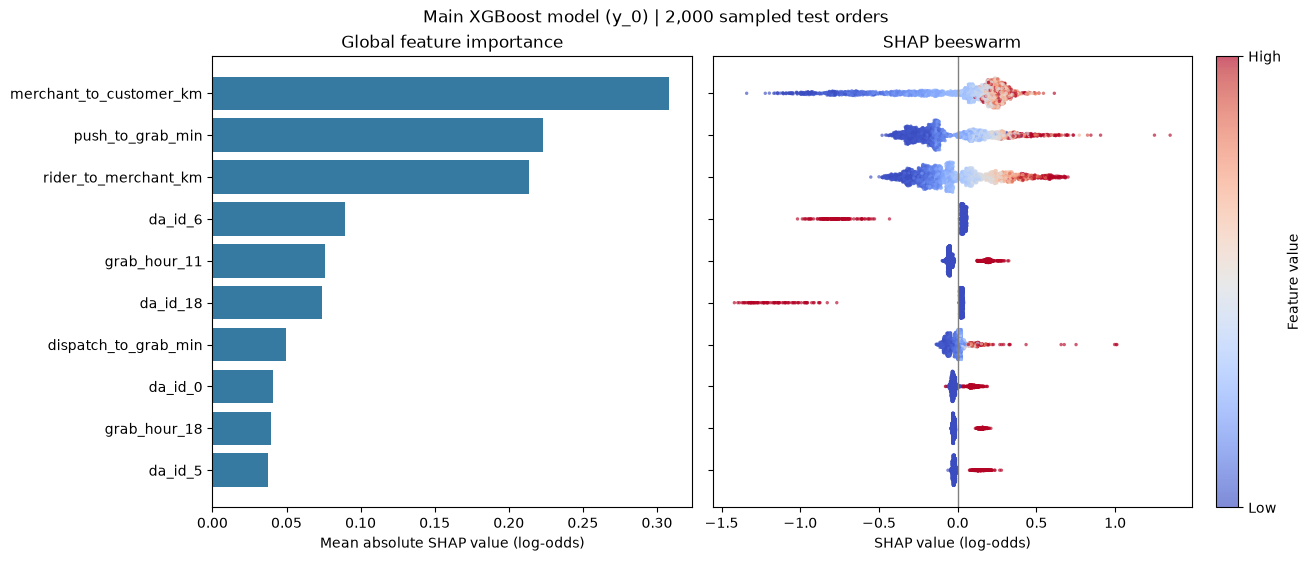

In [45]:
# 全局重要性按编码列统计；点颜色表示特征值高低。
top = importance.head(10)
names = top.index[::-1]
y_positions = np.arange(len(names))

fig, (bar_ax, swarm_ax) = plt.subplots(
    1, 2, figsize=(13, 5.5), sharey=True, layout="constrained",
)

bar_ax.barh(y_positions, top.loc[names], color="#377aa1")
bar_ax.set_yticks(y_positions, labels=names)
bar_ax.set(
    title="Global feature importance",
    xlabel="Mean absolute SHAP value (log-odds)",
)

swarm_ax.axvline(0, color="gray", linewidth=1)
swarm_rng = np.random.default_rng(RANDOM_SEED)

for row, name in enumerate(names):
    values = sample_phi[name].to_numpy()
    feature_values = sample_encoded[:, feature_names.index(name)]

    # 同贡献区间内交错排点，随机种子固定。
    bin_width = max(float(np.ptp(values)) / 50, 1e-12)
    buckets = np.floor((values - values.min()) / bin_width).astype(int)
    offsets = np.zeros(len(values))
    for bucket in np.unique(buckets):
        members = np.flatnonzero(buckets == bucket)
        swarm_rng.shuffle(members)
        slots = np.arange(len(members))
        offsets[members] = ((slots + 1) // 2) * np.where(slots % 2 == 0, -1, 1)
    offsets *= 0.36 / max(np.abs(offsets).max(), 1)

    # 连续特征按 P5–P95 映射颜色，仅影响显示。
    low, high = (
        np.quantile(feature_values, [0.05, 0.95])
        if name in numeric_features else (0, 1)
    )
    colors = np.clip((feature_values - low) / max(float(high - low), 1e-12), 0, 1)
    points = swarm_ax.scatter(
        values, row + offsets, c=colors, cmap="coolwarm",
        vmin=0, vmax=1, s=6, alpha=0.65, linewidths=0,
    )

swarm_ax.set(title="SHAP beeswarm", xlabel="SHAP value (log-odds)")
colorbar = fig.colorbar(points, ax=swarm_ax, ticks=[0, 1])
colorbar.ax.set_yticklabels(["Low", "High"])
colorbar.set_label("Feature value")
fig.suptitle("Main XGBoost model (y_0) | 2,000 sampled test orders")
plt.show()


在抽样的 2,000 笔测试订单中，商家至顾客距离的平均绝对 SHAP 值最高，为 0.3081；其次为推送至接单耗时和骑手至商家距离，分别为 0.2231 和 0.2140。这一排序概括各输入对模型预测的贡献大小。

SHAP 值采用 log-odds 单位，贡献方向由逐笔贡献的正负号表示，平均绝对值汇总贡献大小。排名按编码后的列计算，各小时和区域分别占一列。


In [46]:
# 案例取各结果组按分数排序后的中间订单，同分按 ID 排序。
threshold_10 = validation_thresholds.loc[
    validation_thresholds["method"].eq("XGBoost")
    & validation_thresholds["target_pct"].eq(10),
    "threshold",
].item()

alert = test_scores["xgboost_score"].ge(threshold_10)
late = test_scores["y_0"].eq(1)

case_masks = {
    "Hit (TP)": alert & late,
    "False alarm (FP)": alert & ~late,
    "Miss (FN)": ~alert & late,
}

case_rows = {}
for case, mask in case_masks.items():
    group = test_scores.loc[mask].sort_values(["xgboost_score", "order_id"])
    case_rows[case] = group.index[(len(group) - 1) // 2]

case_index = pd.Index(list(case_rows.values()))
case_phi, case_base, _ = explain_rows(case_index)

case_summary = test_scores.loc[case_index, ["y_0", "xgboost_score"]].copy()
case_summary["alert"] = alert.loc[case_index]
case_summary["log_odds"] = case_base + case_phi.sum(axis=1)

case_summary["distance_km"] = X_test.loc[case_index, "merchant_to_customer_km"]
case_summary["push_to_grab_min"] = X_test.loc[case_index, "push_to_grab_min"]
case_summary.index = list(case_rows)

display(case_summary.round(4))


,y_0,xgboost_score,alert,log_odds,distance_km,push_to_grab_min
Hit (TP),1,0.3001,True,-0.8468,4.0824,4.3167
False alarm (FP),0,0.2904,True,-0.8936,1.8519,4.6667
Miss (FN),1,0.1669,False,-1.6075,1.2162,1.9833


三个案例分别取自命中、误报和漏报组内风险分数居中的订单，用于展示三类预测结果的特征贡献。

| 案例 | 实际晚到 | 模型晚到分数 | 达到阈值 | 最终 log-odds |
|---|---:|---:|---|---:|
| 命中 | 是 | 30.01% | 是 | -0.8468 |
| 误报 | 否 | 29.04% | 是 | -0.8936 |
| 漏报 | 是 | 16.69% | 否 | -1.6075 |


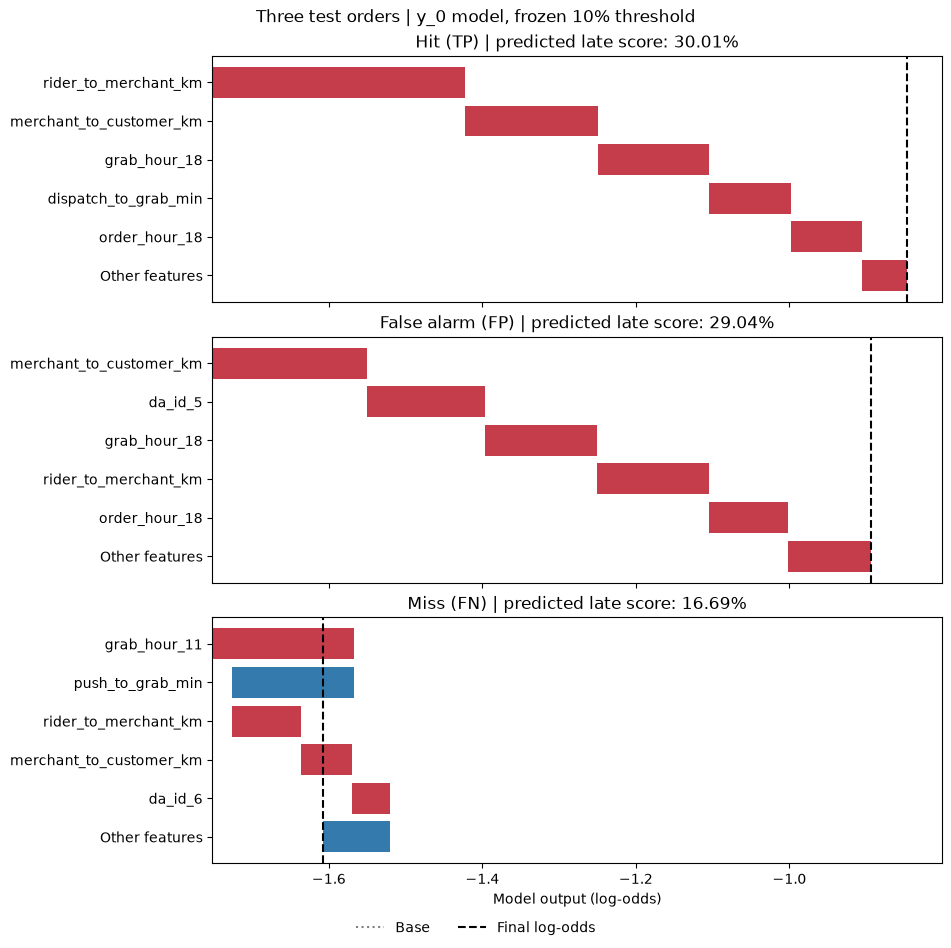

In [47]:
# 展示绝对贡献最大的五列，其余列合并；贡献单位为 log-odds。
fig, axes = plt.subplots(
    3, 1, figsize=(9.4, 9.4), sharex=True, layout="constrained",
)

for ax, (case, index) in zip(axes, case_rows.items()):
    phi = case_phi.loc[index]

    largest = phi.loc[phi.abs().nlargest(5).index]
    steps = pd.concat([
        largest,
        pd.Series({"Other features": phi.sum() - largest.sum()}),
    ])

    base = float(case_base.loc[index])
    ends = base + steps.cumsum()
    starts = ends - steps

    ax.barh(
        steps.index, steps, left=starts,
        color=np.where(steps.ge(0), "#c53c4a", "#347aad"),
    )
    ax.axvline(base, color="gray", linestyle=":", label="Base")
    ax.axvline(ends.iloc[-1], color="black", linestyle="--", label="Final log-odds")
    ax.invert_yaxis()

    score = test_scores.loc[index, "xgboost_score"]
    ax.set_title(f"{case} | predicted late score: {score:.2%}")

axes[-1].set_xlabel("Model output (log-odds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Three test orders | y_0 model, frozen 10% threshold")
plt.show()


命中案例中，骑手接单位置距商家约 1.56 公里，对应最大的正向 SHAP 贡献，约 +0.328；约 4.08 公里的配送距离贡献 +0.174。最终分数为 30.01%，超过固定阈值，订单实际晚到。

误报案例中，约 1.85 公里的配送距离贡献 +0.201，区域 5 的编码列贡献 +0.154；18 点接单及骑手至商家距离也提高分数。最终分数为 29.04%，触发预警，但订单准时送达。

漏报案例中，11 点接单的编码列贡献 +0.185，约 1.98 分钟的推送至接单耗时贡献 −0.159。最终分数为 16.69%，低于阈值，订单实际晚到。各项贡献展示模型组合输入并形成风险分数的过程；实际延迟机制需要结合调度与履约记录分析。


## 11. 分组误差分析

本节固定使用 `y_0` XGBoost 的 10% 验证目标阈值，按预约类型、接单时段、距离和测试日期汇总。FPR 的分母为组内实际准时订单，FNR 的分母为组内实际晚到订单；同时保留订单数及误报、漏报笔数。


In [48]:
# 使用主模型固定阈值，构造互斥的 TP、FP、FN、TN 标记。
error_rows = test_scores[
    ["order_id", "grab_date", "y_0", "xgboost_score"]
].copy()

alert = error_rows["xgboost_score"].ge(threshold_10)
late = error_rows["y_0"].eq(1)

error_rows["TP"] = (alert & late).astype(int)
error_rows["FP"] = (alert & ~late).astype(int)
error_rows["FN"] = (~alert & late).astype(int)
error_rows["TN"] = (~alert & ~late).astype(int)

error_rows["booking_type"] = df_test["is_prebook"].map({
    0: "On-demand",
    1: "Prebooked",
})

error_rows["accept_period"] = pd.cut(
    df_test["grab_time_dt"].dt.hour,
    bins=[0, 6, 10, 14, 17, 21, 24],
    labels=["00–06", "06–10", "10–14", "14–17", "17–21", "21–24"],
    right=False,
)

error_rows["distance_band"] = pd.cut(
    df_test["merchant_to_customer_km"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=["[0, 1)", "[1, 2)", "[2, 3)", "[3, 5)", "[5, ∞)"],
    right=False,
)

error_rows["test_date"] = error_rows["grab_date"].dt.strftime("%m-%d")

count_cols = ["TP", "FP", "FN", "TN"]

assert error_rows[count_cols].sum(axis=1).eq(1).all()


In [49]:
# FPR 以实际准时数为分母，FNR 以实际晚到数为分母。
def add_error_rates(counts):
    table = counts.copy()

    table["on_time_n"] = table["FP"] + table["TN"]
    table["late_n"] = table["FN"] + table["TP"]
    table["orders"] = table["on_time_n"] + table["late_n"]

    table["alert_pct"] = 100 * (table["TP"] + table["FP"]) / table["orders"]

    # 分母为零时保留缺失，避免产生无意义的错误率。
    table["fpr_pct"] = 100 * table["FP"] / table["on_time_n"].replace(0, np.nan)
    table["fnr_pct"] = 100 * table["FN"] / table["late_n"].replace(0, np.nan)
    return table


overall_errors = add_error_rates(
    error_rows[count_cols].sum().to_frame().T
)
display(overall_errors.round(2))

breakdowns = {
    "Booking type": "booking_type",
    "Acceptance period": "accept_period",
    "Distance (km)": "distance_band",
    "Test date": "test_date",
}

group_tables = {}
show_cols = ["orders", "on_time_n", "late_n", "FP", "FN", "alert_pct", "fpr_pct", "fnr_pct"]

for title, col in breakdowns.items():
    grouped_counts = (
        error_rows.groupby(col, observed=True, dropna=False)[count_cols]
        .sum()
    )
    group_tables[title] = add_error_rates(grouped_counts)

    print(title)
    display(group_tables[title][show_cols].round(2))


Booking type
Acceptance period
Distance (km)
Test date


,TP,FP,FN,TN,on_time_n,late_n,orders,alert_pct,fpr_pct,fnr_pct
0,4457,10086,17465,113060,123146,21922,145068,10.02,8.19,79.67


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
booking_type,,,,,,,,
On-demand,139779,118945,20834,9260,16736,9.56,7.79,80.33
Prebooked,5289,4201,1088,826,729,22.40,19.66,67.00


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
accept_period,,,,,,,,
00–06,3597,3166,431,123,357,5.48,3.89,82.83
06–10,8338,7315,1023,164,912,3.30,2.24,89.15
10–14,56744,48382,8362,3455,7059,8.39,7.14,84.42
14–17,17167,14878,2289,370,2076,3.40,2.49,90.69
17–21,48860,40466,8394,5636,5802,16.84,13.93,69.12
21–24,10362,8939,1423,338,1259,4.84,3.78,88.48


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
distance_band,,,,,,,,
"[0, 1)",43856,39984,3872,618,3553,2.14,1.55,91.76
"[1, 2)",57281,48189,9092,3873,7441,9.64,8.04,81.84
"[2, 3)",33221,26607,6614,3996,4963,17.00,15.02,75.04
"[3, 5)",9213,7220,1993,1377,1299,22.48,19.07,65.18
"[5, ∞)",1497,1146,351,222,209,24.32,19.37,59.54


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
test_date,,,,,,,,
10-23,77719,64811,12908,5444,10254,10.42,8.40,79.44
10-24,67349,58335,9014,4642,7211,9.57,7.96,80.00


| 结果 | 笔数 |
|---|---:|
| 命中 TP | 4,457 |
| 误报 FP | 10,086 |
| 漏报 FN | 17,465 |
| 正确放行 TN | 113,060 |
| 合计 | 145,068 |

总体误报率 FPR = 10,086 / 123,146 = 8.19%，分母为实际准时订单；漏报率 FNR = 17,465 / 21,922 = 79.67%，分母为实际晚到订单。FPR 衡量实际准时订单受到误报影响的比例；FNR 等于 1 减去覆盖率。在当前监控容量下，大部分晚到订单落在阈值以下。


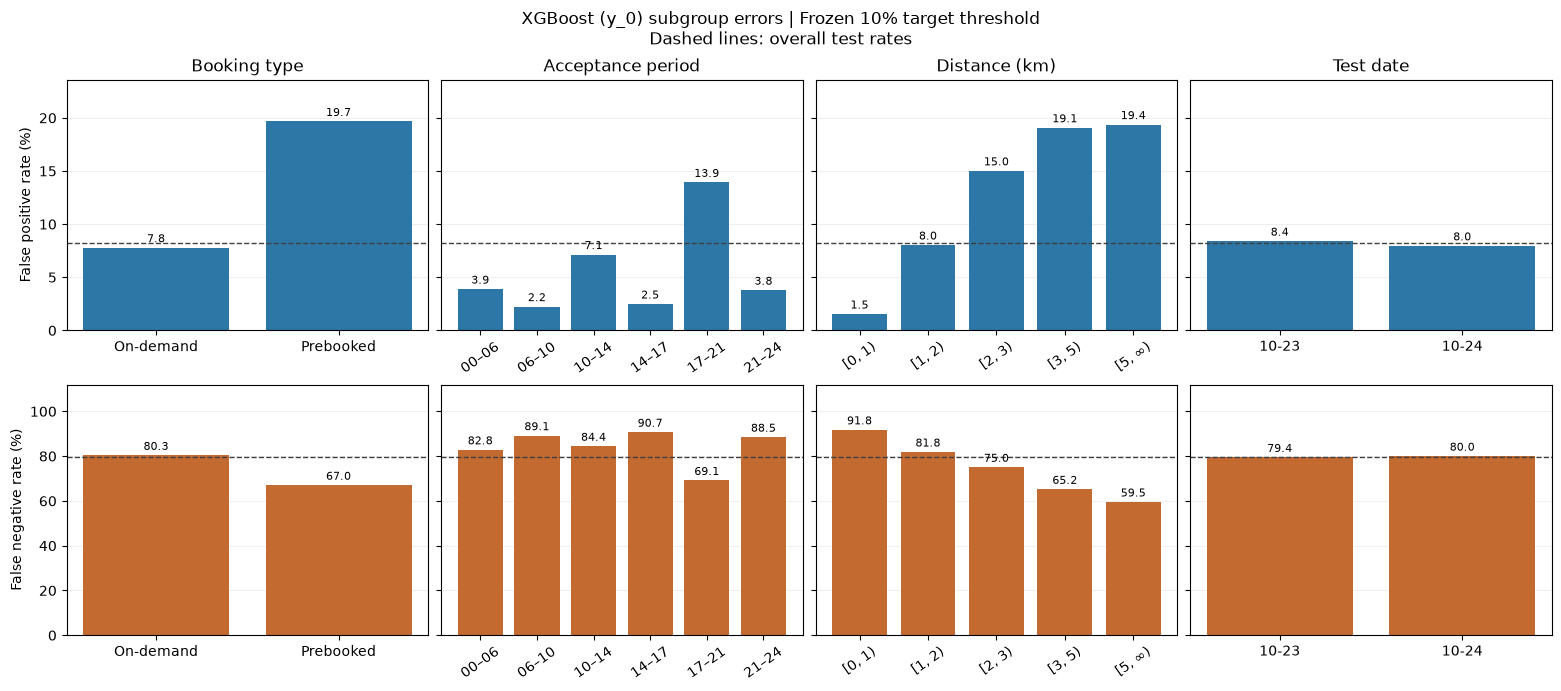

In [50]:
fig, axes = plt.subplots(
    2, 4, figsize=(15.5, 6.8), sharey="row", layout="constrained",
)

for j, (title, table) in enumerate(group_tables.items()):
    labels = table.index.astype(str).tolist()
    positions = np.arange(len(labels))

    for i, (metric, color) in enumerate([
        ("fpr_pct", "#2c77a6"),
        ("fnr_pct", "#c36a31"),
    ]):
        ax = axes[i, j]
        bars = ax.bar(positions, table[metric], color=color)

        ax.axhline(
            overall_errors[metric].iloc[0],
            color="#404040", linestyle="--", linewidth=1,
        )
        ax.set_xticks(positions, labels, rotation=35 if j in (1, 2) else 0)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

        if i == 0:
            ax.set_title(title)

axes[0, 0].set_ylabel("False positive rate (%)")
axes[1, 0].set_ylabel("False negative rate (%)")

max_fpr = max(table["fpr_pct"].max() for table in group_tables.values())
axes[0, 0].set_ylim(0, 1.20 * max_fpr)
axes[1, 0].set_ylim(0, 112)

fig.suptitle(
    "XGBoost (y_0) subgroup errors | Frozen 10% target threshold\n"
    "Dashed lines: overall test rates"
)
plt.show()


预约订单的 FPR 为 19.66%，高于非预约订单的 7.79%；其 FNR 为 67.00%，低于非预约订单的 80.33%。两组实际监控率分别为 22.40% 和 9.56%。这些差异同时反映了预警负担与漏报水平。

17:00–20:59 的 FPR 最高，为 13.93%，包含 5,636 笔误报，占全部误报的 55.88%。14:00–16:59 的 FNR 最高，为 90.69%；10:00–13:59 的漏报笔数最多，为 7,059 笔。组内错误率与错误总量回答不同问题。

距离不足 1 公里的订单 FNR 为 91.76%。[1, 2) 公里组 FNR 为 81.84%，订单基数为 57,281 笔，包含 9,092 笔实际晚到，最终漏报 7,441 笔。该组漏报总量最高，反映较大的业务核查负担；组内漏报比例则低于不足 1 公里组。10 月 23 日和 24 日的 FNR 分别为 79.44% 和 80.00%。

### 运营含义

预约组较高的 FPR 将复核重点指向其风险分数分布及记录 ETA 特征，具体成因还需逐单检查。17–21 点的误报量可用于估计高峰预警处理负担；14–17 点的高 FNR 提示需要复核该时段漏报。[1, 2) 公里组则应结合订单基数评估总漏报负担。这些诊断用于确定后续检查方向，测试阈值沿用验证阶段的设定。


## 12. 接单时的 ETA 提前量

定义 `lead_min = (estimate_arrived_time - grab_time) / 60`，相对于数据中记录的 ETA 计算。提前量大于 0 表示接单早于 ETA；小于或等于 0 的命中归入已到或超过 ETA 的预警。分位数与至少 5、10、15 分钟的比例仅在正提前量子集中计算。


In [51]:
# 提前量相对于记录 ETA 计算，仅用于回溯评估。
lead_rows = error_rows[["order_id", "TP", "FP"]].copy()

time_cols = ["estimate_arrived_time", "grab_time"]
lead_rows[time_cols] = df_test.loc[lead_rows.index, time_cols]

lead_rows["lead_min"] = (
    lead_rows["estimate_arrived_time"] - lead_rows["grab_time"]
) / 60

all_alerts = lead_rows["TP"].eq(1) | lead_rows["FP"].eq(1)
hit_alerts = lead_rows["TP"].eq(1)

remaining_by_group = {
    "All test orders": lead_rows["lead_min"],
    "All alerts": lead_rows.loc[all_alerts, "lead_min"],
    "Hit alerts": lead_rows.loc[hit_alerts, "lead_min"],
}

# 已到或超过 ETA 的订单单列，不计为 ETA 前预警。
at_or_past_eta_orders = lead_rows.loc[lead_rows["lead_min"].le(0)].copy()

eta_rows = []
for group, remaining in remaining_by_group.items():
    at_or_past_eta = remaining.le(0)
    eta_rows.append({
        "group": group,
        "total": len(remaining),
        "positive_lead": remaining.gt(0).sum(),
        "exactly_eta": remaining.eq(0).sum(),
        "past_eta": remaining.lt(0).sum(),
        "at_or_past_eta": at_or_past_eta.sum(),
        "at_or_past_pct": 100 * at_or_past_eta.mean(),
    })

eta_status = pd.DataFrame(eta_rows).set_index("group")
display(eta_status.round(2))


,total,positive_lead,exactly_eta,past_eta,at_or_past_eta,at_or_past_pct
group,,,,,,
All test orders,145068,144924,1,143,144,0.10
All alerts,14543,14462,1,80,81,0.56
Hit alerts,4457,4376,1,80,81,1.82


In [52]:
# 分位数与时间窗口比例仅使用正提前量订单。
positive_groups = {}
for group in ["All alerts", "Hit alerts"]:
    remaining = remaining_by_group[group]
    positive_groups[group] = remaining.loc[remaining.gt(0)]

quantile_levels = {"P10": 0.10, "P25": 0.25, "P50": 0.50,
                   "P75": 0.75, "P90": 0.90}
minutes = [5, 10, 15]
quantile_rows = []
window_rows = []

for group, remaining in positive_groups.items():
    quantile_row = {"group": group, "positive_lead_n": len(remaining)}
    for name, level in quantile_levels.items():
        quantile_row[name] = remaining.quantile(level)
    quantile_rows.append(quantile_row)

    for cutoff in minutes:
        # 使用未取整分钟数，时间门槛包含等号。
        count = remaining.ge(cutoff).sum()
        window_rows.append({
            "group": group,
            "min_required": cutoff,
            "positive_lead_n": len(remaining),
            "n_at_least": count,
            "pct_at_least": 100 * count / len(remaining),
        })

lead_quantiles = pd.DataFrame(quantile_rows).set_index("group")
lead_windows = pd.DataFrame(window_rows)

display(lead_quantiles.round(2))
display(lead_windows.round(2))


,positive_lead_n,P10,P25,P50,P75,P90
group,,,,,,
All alerts,14462,26.05,31.33,38.07,44.43,50.45
Hit alerts,4376,20.76,28.40,35.43,42.32,47.78


,group,min_required,positive_lead_n,n_at_least,pct_at_least
0,All alerts,5,14462,14430,99.78
1,All alerts,10,14462,14348,99.21
2,All alerts,15,14462,14202,98.20
3,Hit alerts,5,4376,4344,99.27
4,Hit alerts,10,4376,4264,97.44
5,Hit alerts,15,4376,4147,94.77


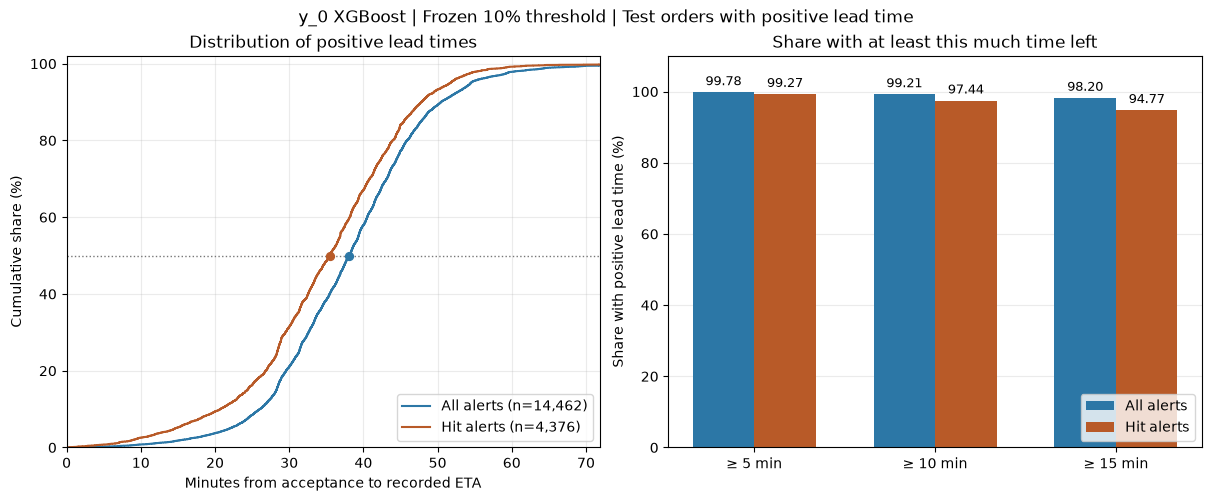

In [53]:
# 经验累计分布使用全部正提前量订单，纵轴为组内累计比例。
fig, (cdf_ax, window_ax) = plt.subplots(
    1, 2, figsize=(12, 4.9), layout="constrained",
)
colors = {"All alerts": "#2c77a6", "Hit alerts": "#b85a28"}

for group, remaining in positive_groups.items():
    sorted_minutes = remaining.sort_values().to_numpy()
    x = np.r_[0, sorted_minutes]
    y = 100 * np.arange(len(x)) / len(sorted_minutes)
    cdf_ax.step(
        x, y, where="post", color=colors[group],
        label=f"{group} (n={len(remaining):,})",
    )

    median = lead_quantiles.loc[group, "P50"]
    cdf_ax.scatter(median, 50, color=colors[group], s=32, zorder=3)

cdf_ax.axhline(50, color="#777777", linestyle=":", linewidth=1)

# P99.5 仅限制显示范围，不排除统计样本。
right_edge = max(remaining.quantile(0.995) for remaining in positive_groups.values())
cdf_ax.set(
    xlim=(0, right_edge), ylim=(0, 102),
    xlabel="Minutes from acceptance to recorded ETA",
    ylabel="Cumulative share (%)",
    title="Distribution of positive lead times",
)
cdf_ax.legend(loc="lower right")
cdf_ax.grid(alpha=0.25)

# 柱形图比例以各组正提前量订单数为分母。
positions = np.arange(len(minutes))
width = 0.34

for j, group in enumerate(positive_groups):
    percentages = lead_windows.loc[
        lead_windows["group"].eq(group), "pct_at_least"
    ]
    bars = window_ax.bar(
        positions + (j - 0.5) * width,
        percentages, width, color=colors[group], label=group,
    )
    window_ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

window_ax.set_xticks(positions, [f"≥ {cutoff} min" for cutoff in minutes])
window_ax.set(
    ylim=(0, 110),
    ylabel="Share with positive lead time (%)",
    title="Share with at least this much time left",
)
window_ax.legend(loc="lower right")
window_ax.grid(axis="y", alpha=0.25)
window_ax.set_axisbelow(True)

fig.suptitle("y_0 XGBoost | Frozen 10% threshold | Test orders with positive lead time")
plt.show()


在 4,457 笔命中订单中，**4,376 笔在接单时仍有正 ETA 提前量**，占全部命中的 98.18%；**81 笔已到或超过记录 ETA**，其中 1 笔恰好到达 ETA、80 笔已超过 ETA；这部分单独列为已到或超过 ETA 的命中。

正提前量命中的中位提前量为 35.43 分钟；全部正提前量预警的中位数为 38.07 分钟。命中订单中有 **4,147 笔至少提前 15 分钟**，占正提前量命中的 94.77%，占全部命中的 93.04%。右图的比例以各组正提前量订单为分母。这些提前量以数据表中的记录 ETA 为参照。评估实际处置时间还需核验接单时可见的 ETA 版本，并计入信息传递和人工响应所需的时间。


## 13. 概率预测诊断

使用 Brier 分数和等宽分箱曲线检验原始 XGBoost 分数。常数基准为训练集 `y_0` 正例率，验证、测试阶段使用同一常数。分箱曲线同时报告各箱订单数，以区分校准偏差与小样本波动。


In [54]:
# 常数概率基准仅使用训练集晚到率，验证与测试复用该值。
from sklearn.metrics import brier_score_loss

score_sets = {
    "Validation": validation_scores,
    "Test": test_scores,
}

train_late_rate = y_train["y_0"].mean()
brier_rows = []

for split, scores in score_sets.items():
    y_true = scores["y_0"]
    p = scores["xgboost_score"]

    p_base = np.full(len(scores), train_late_rate)

    brier_rows.append({
        "split": split,
        "orders": len(scores),
        "mean_score_pct": 100 * p.mean(),
        "actual_late_pct": 100 * y_true.mean(),
        "xgboost_brier": brier_score_loss(y_true, p),
        "constant_brier": brier_score_loss(y_true, p_base),
    })

brier_summary = pd.DataFrame(brier_rows).set_index("split")
print(f"常数基准使用的训练集晚到率为 {train_late_rate:.2%}")
display(brier_summary.round(5))


常数基准使用的训练集晚到率为 14.85%


,orders,mean_score_pct,actual_late_pct,xgboost_brier,constant_brier
split,,,,,
Validation,84756,15.00174,15.40776,0.12215,0.13037
Test,145068,14.98176,15.11153,0.12128,0.12829


In [55]:
# 分箱右闭，首箱包含零；各箱同时报告样本量与校准偏差。
bin_edges = np.linspace(0, 1, 11)
bin_labels = [f"{lo}–{lo + 10}%" for lo in range(0, 100, 10)]
calibration_tables = {}

for split, scores in score_sets.items():
    binned = scores.assign(score_bin=pd.cut(
        scores["xgboost_score"],
        bins=bin_edges,
        labels=bin_labels,
        include_lowest=True,
    ))

    table = binned.groupby("score_bin", observed=True).agg(
        orders=("y_0", "size"),
        mean_score=("xgboost_score", "mean"),
        late_rate=("y_0", "mean"),
    )

    # 差值为实际晚到率减平均分数，单位为百分点。
    table["gap_pp"] = 100 * (table["late_rate"] - table["mean_score"])
    calibration_tables[split] = table

    print(split)
    display(table.assign(
        mean_score_pct=100 * table["mean_score"].astype(float),
        actual_late_pct=100 * table["late_rate"],
    )[["orders", "mean_score_pct", "actual_late_pct", "gap_pp"]].round(2))


Validation
Test


,orders,mean_score_pct,actual_late_pct,gap_pp
score_bin,,,,
0–10%,25011,5.67,5.30,-0.36
10–20%,38375,14.96,15.56,0.60
20–30%,17705,23.93,24.60,0.67
30–40%,3117,33.27,34.65,1.38
40–50%,315,43.36,52.06,8.70
50–60%,90,54.25,58.89,4.64
60–70%,89,64.60,68.54,3.94
70–80%,49,74.79,93.88,19.09
80–90%,5,81.39,40.00,-41.39


,orders,mean_score_pct,actual_late_pct,gap_pp
score_bin,,,,
0–10%,43045,5.63,5.79,0.17
10–20%,65377,14.96,15.32,0.36
20–30%,30422,23.92,23.61,-0.31
30–40%,5230,33.29,31.97,-1.32
40–50%,594,43.58,47.14,3.56
50–60%,149,54.22,61.74,7.53
60–70%,113,65.04,61.06,-3.98
70–80%,132,74.74,84.85,10.11
80–90%,6,82.27,100.00,17.73


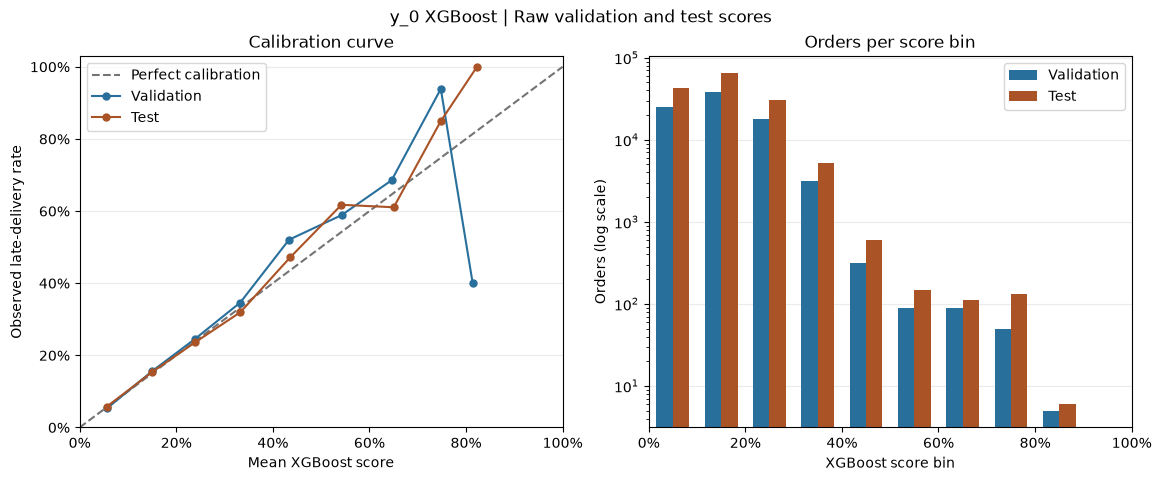

In [56]:
# 校准曲线按非空分箱绘制；样本量采用对数轴并跳过空箱。
from matplotlib.ticker import PercentFormatter

fig, (cal_ax, count_ax) = plt.subplots(
    1, 2, figsize=(11.5, 4.7), layout="constrained",
)

cal_ax.plot([0, 1], [0, 1], "--", color="#747474", label="Perfect calibration")

centers = (bin_edges[:-1] + bin_edges[1:]) / 2
width = 0.034
colors = {"Validation": "#296f9c", "Test": "#a95327"}

for j, (split, table) in enumerate(calibration_tables.items()):
    cal_ax.plot(
        table["mean_score"], table["late_rate"],
        marker="o", markersize=5, color=colors[split], label=split,
    )

    counts = table["orders"].reindex(bin_labels, fill_value=0).to_numpy()
    has_orders = counts > 0
    count_ax.bar(
        centers[has_orders] + (j - 0.5) * width,
        counts[has_orders],
        width=width, color=colors[split], label=split,
    )

cal_ax.set(
    xlim=(0, 1), ylim=(0, 1.03),
    xlabel="Mean XGBoost score", ylabel="Observed late-delivery rate",
    title="Calibration curve",
)
cal_ax.yaxis.set_major_formatter(PercentFormatter(1))
cal_ax.legend(loc="upper left")

count_ax.set(
    xlim=(0, 1), yscale="log",
    xlabel="XGBoost score bin", ylabel="Orders (log scale)",
    title="Orders per score bin",
)
count_ax.legend(loc="upper right")

for ax in (cal_ax, count_ax):
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("y_0 XGBoost | Raw validation and test scores")
plt.show()


测试集 XGBoost 的 Brier 分数为 0.12128，低于以训练集晚到率作为常数预测的 0.12829；验证集对应值为 0.12214 和 0.13037。Brier 分数汇总概率预测的均方误差，数值越低误差越小；分箱曲线进一步展示各风险区间的平均预测与实际晚到率。

测试集 30%–40% 分数档的平均预测为 33.29%，实际晚到率为 31.97%，高估约 1.32 个百分点。99.31% 的测试订单位于不超过 40% 的分数档，较高分数档样本较少，分箱晚到率的波动需结合订单数解读。


## 14. 主分析结果导出与一致性检查

导出测试订单的风险分数、预警标记、事后结果、业务分组和记录 ETA 提前量，并生成整体与逐日指标。CSV 保留完整分数和阈值精度；读回后检查订单唯一性、逐单阈值判断，以及命中数和 Brier 分数与前文一致。订单级文件中的真实标签和结果属于事后评估信息。

同时导出逐日划分构成 `main_split_balance.csv`、主标签验证排序指标 `main_validation_metrics.csv`，以及两种标签的测试容量比较 `main_capacity_metrics.csv`。第 15–16 节另导出滚动回测和种子敏感性汇总。


In [57]:
# 保留逐单风险分数的完整精度，避免改变阈值附近的预警判断。
dashboard_orders = (
    test_scores[["order_id", "grab_date", "xgboost_score", "y_0"]]
    .rename(columns={"xgboost_score": "risk_score"})
    .copy()
)

dashboard_orders["order_id"] = dashboard_orders["order_id"].astype("string")
dashboard_orders["grab_date"] = dashboard_orders["grab_date"].dt.strftime("%Y-%m-%d")

dashboard_orders["risk_score"] = dashboard_orders["risk_score"].astype(float)

alerted = dashboard_orders["risk_score"].ge(threshold_10)
actual_late = dashboard_orders["y_0"].eq(1)
dashboard_orders["alert"] = alerted.astype("int8")

dashboard_orders["outcome"] = np.select(
    [alerted & actual_late, alerted & ~actual_late, ~alerted & actual_late],
    ["TP", "FP", "FN"],
    default="TN",
)

# 在排序前按原始索引对齐分组和提前量。
filter_cols = ["booking_type", "accept_period", "distance_band"]
dashboard_orders[filter_cols] = error_rows.loc[dashboard_orders.index, filter_cols]
dashboard_orders["lead_min"] = lead_rows.loc[dashboard_orders.index, "lead_min"]

# 同分按 ID 排序，固定导出顺序。
dashboard_orders = dashboard_orders.sort_values(
    ["risk_score", "order_id"], ascending=[False, True], ignore_index=True,
)

print(f"测试订单数 {len(dashboard_orders):,}")
print(f"预警笔数 {dashboard_orders['alert'].sum():,}")
display(dashboard_orders.head())


测试订单数 145,068
预警笔数 14,543


,order_id,grab_date,risk_score,y_0,alert,outcome,booking_type,accept_period,distance_band,lead_min
0,212568,2022-10-24,0.852073,1,1,TP,On-demand,17–21,"[0, 1)",9.866667
1,200265,2022-10-23,0.851474,1,1,TP,On-demand,17–21,"[2, 3)",-25.550000
2,275541,2022-10-23,0.812707,1,1,TP,On-demand,10–14,"[0, 1)",1.383333
3,315204,2022-10-23,0.811422,1,1,TP,On-demand,17–21,"[1, 2)",7.016667
4,131299,2022-10-23,0.805303,1,1,TP,On-demand,17–21,"[2, 3)",24.050000


In [58]:
# 整体与逐日指标分别重算，保持各项比例的分母一致。
def summarize_dashboard(orders, scope):
    counts = orders["outcome"].value_counts()
    tp, fp, fn, tn = (
        int(counts.get(code, 0)) for code in ["TP", "FP", "FN", "TN"]
    )
    n = len(orders)
    alerts = tp + fp
    late_orders = tp + fn

    y_true = orders["y_0"]
    risk_score = orders["risk_score"]

    # 已到或超过 ETA 的命中单列；中位数仅用正提前量命中。
    hit_lead = orders.loc[orders["outcome"].eq("TP"), "lead_min"]
    positive_hit_lead = hit_lead[hit_lead.gt(0)]

    return {
        "scope": scope,
        "start_date": orders["grab_date"].min(),
        "end_date": orders["grab_date"].max(),
        "model": "XGBoost",
        "target": "y_0",
        "target_alert_pct": 10,
        "threshold": threshold_10,
        "orders": n,
        "late_orders": late_orders,
        "late_pct": 100 * late_orders / n,
        "alerts": alerts,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,

        # 百分比均以 0–100 存储；精确率与覆盖率分母不同。
        "actual_alert_pct": 100 * alerts / n,
        "precision_pct": 100 * tp / alerts if alerts else np.nan,
        "coverage_pct": 100 * tp / late_orders if late_orders else np.nan,
        "fpr_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
        "fnr_pct": 100 * fn / late_orders if late_orders else np.nan,

        "ap": average_precision_score(y_true, risk_score),
        "roc_auc": roc_auc_score(y_true, risk_score),
        "brier": brier_score_loss(y_true, risk_score),
        "hits_at_or_past_eta": int(hit_lead.le(0).sum()),
        "positive_lead_hits": len(positive_hit_lead),
        "median_positive_hit_lead_min": positive_hit_lead.median(),
        "hits_at_least_15min": int(positive_hit_lead.ge(15).sum()),
    }


summary_rows = [summarize_dashboard(dashboard_orders, "overall")]
for _, day_orders in dashboard_orders.groupby("grab_date", sort=True):
    summary_rows.append(summarize_dashboard(day_orders, "daily"))

dashboard_metrics = pd.DataFrame(summary_rows)

display(dashboard_metrics[[
    "scope", "start_date", "end_date", "orders", "late_orders",
    "alerts", "tp", "actual_alert_pct", "precision_pct", "coverage_pct",
]].round(2))


,scope,start_date,end_date,orders,late_orders,alerts,tp,actual_alert_pct,precision_pct,coverage_pct
0,overall,2022-10-23,2022-10-24,145068,21922,14543,4457,10.02,30.65,20.33
1,daily,2022-10-23,2022-10-23,77719,12908,8098,2654,10.42,32.77,20.56
2,daily,2022-10-24,2022-10-24,67349,9014,6445,1803,9.57,27.98,20.00


In [59]:
# 创建结果目录并导出；读回后核对标识、阈值判断及汇总指标。
output_dir = Path("../results").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

order_path = output_dir / "dashboard_order_scores.csv"
metric_path = output_dir / "dashboard_metrics.csv"

dashboard_orders.to_csv(order_path, index=False, encoding="utf-8")
dashboard_metrics.to_csv(metric_path, index=False, encoding="utf-8")

# ID 按文本读入，浮点数按完整精度往返。
orders_read = pd.read_csv(
    order_path, dtype={"order_id": "string"}, float_precision="round_trip",
)
metrics_read = pd.read_csv(metric_path, float_precision="round_trip")

overall = metrics_read.loc[metrics_read["scope"].eq("overall")].iloc[0]
previous = test_fixed.loc[
    test_fixed["method"].eq("XGBoost") & test_fixed["target_pct"].eq(10)
].iloc[0]

assert len(orders_read) == overall["orders"]
assert orders_read["order_id"].is_unique
assert orders_read["order_id"].equals(dashboard_orders["order_id"])

# 用读回分数逐单验证预警，避免导出舍入改变分类。
assert overall["threshold"] == threshold_10
assert orders_read["alert"].eq(
    orders_read["risk_score"].ge(overall["threshold"])
).all()

assert orders_read["alert"].sum() == overall["alerts"] == previous["monitored"]
assert orders_read["outcome"].eq("TP").sum() == overall["tp"] == previous["hits"]
assert np.isclose(overall["brier"], brier_summary.loc["Test", "xgboost_brier"])

print(f"订单明细 {len(orders_read):,} 行，指标汇总 {len(metrics_read)} 行")
print(f"读回阈值 {overall['threshold']:.10f}")
print(f"核对通过，共 {int(overall['alerts']):,} 笔预警，"
      f"其中 {int(overall['tp']):,} 笔命中")
print(order_path)
print(metric_path)

# 保存可共享的汇总证据，逐单评分仍为本地输出。
main_split_balance.to_csv(output_dir / "main_split_balance.csv", index=False)
model_comparison.to_csv(output_dir / "main_validation_metrics.csv", index=False)
main_capacity_metrics = pd.concat([
    test_fixed.assign(label="y_0"),
    test_fixed_y8.assign(label="y_8"),
], ignore_index=True)
main_capacity_metrics.to_csv(output_dir / "main_capacity_metrics.csv", index=False)


订单明细 145,068 行，指标汇总 3 行
读回阈值 0.2573448718
核对通过，共 14,543 笔预警，其中 4,457 笔命中
/Users/chronus/code/ai-bigdata-project/results/dashboard_order_scores.csv
/Users/chronus/code/ai-bigdata-project/results/dashboard_metrics.csv


## 15. 三折滚动前瞻回测

三折均按“较早日期训练 → 下一日验证 → 再下一日测试”的顺序模拟预测。每折重新拟合预处理器和固定参数模型，训练标签须在验证日零点前揭晓，验证标签须在测试日零点前揭晓；测试标签可事后观察。四种方法均在该折验证集确定 5%、10%、20% 容量阈值，再固定应用于测试日。

| 折 | 训练接单期 | 验证日 | 测试日 | 训练 / 验证 / 测试订单数 |
|---|---|---|---|---:|
| 1 | 10 月 17–20 日 | 10 月 21 日（周五） | 10 月 22 日（周六） | 273,260 / 71,757 / 77,637 |
| 2 | 10 月 17–21 日 | 10 月 22 日（周六） | 10 月 23 日（周日） | 345,355 / 77,230 / 77,719 |
| 3 | 10 月 17–22 日 | 10 月 23 日（周日） | 10 月 24 日（周一） | 423,008 / 77,349 / 67,349 |

各折的训练标签截止规则分别排除 338、423、407 笔，验证标签截止规则分别排除 423、407、370 笔。测试日使用整日有效样本，因此第一折测试包含 407 笔在次日才完成的订单；第二折验证按当时的标签可得性将这些订单排除。

第一、二折仍检验工作日训练向周末的迁移；第三折训练已包含周六。三折用于观察同一个周末及相邻日期的工作量和识别表现。各折训练窗口重叠，与主方案共同构成这一历史窗口内的多种评估。


In [60]:
# 三折滚动前瞻回测：每折仅用测试日前已经揭晓的标签。
from sklearn.base import clone

rolling_fold_specs = [
    {
        "fold": "Fold 1",
        "train_start": "2022-10-17",
        "validation_date": "2022-10-21",
        "test_date": "2022-10-22",
    },
    {
        "fold": "Fold 2",
        "train_start": "2022-10-17",
        "validation_date": "2022-10-22",
        "test_date": "2022-10-23",
    },
    {
        "fold": "Fold 3",
        "train_start": "2022-10-17",
        "validation_date": "2022-10-23",
        "test_date": "2022-10-24",
    },
]
rolling_capacities = [5, 10, 20]
rolling_split_rows = []
rolling_metric_rows = []


def rolling_scores(frame, features, transformed, transformed_xgb,
                   logistic_model, xgboost_model, distance_fill, random_scores):
    """Build an index-aligned score table without changing the main analysis objects."""
    table = frame[["order_id", "y_0"]].sort_values("order_id").copy()
    table["random_score"] = pd.Series(random_scores, index=table.index)
    table["distance_score_km"] = features["merchant_to_customer_km"].fillna(
        distance_fill
    )
    table["logistic_score"] = pd.Series(
        logistic_model.predict_proba(transformed)[:, 1], index=features.index,
    )
    table["xgboost_score"] = pd.Series(
        xgboost_model.predict_proba(transformed_xgb)[:, 1], index=features.index,
    )
    assert table.notna().all().all()
    return table


for fold_number, spec in enumerate(rolling_fold_specs, start=1):
    fold_train_start = pd.Timestamp(spec["train_start"], tz=tz)
    fold_validation_start = pd.Timestamp(spec["validation_date"], tz=tz)
    fold_test_start = pd.Timestamp(spec["test_date"], tz=tz)
    fold_test_end = fold_test_start + pd.Timedelta(days=1)

    fold_train_window = (
        df_clean["grab_date"].ge(fold_train_start)
        & df_clean["grab_date"].lt(fold_validation_start)
    )
    fold_validation_window = df_clean["grab_date"].eq(fold_validation_start)
    fold_test_window = df_clean["grab_date"].eq(fold_test_start)

    # 拟合和选阈值时，只使用各自截止点前已经送达的订单。
    fold_train_mask = fold_train_window & df_clean["arrive_time_dt"].lt(
        fold_validation_start
    )
    fold_validation_mask = (
        fold_validation_window
        & df_clean["arrive_time_dt"].lt(fold_test_start)
    )

    fold_train = df_clean.loc[fold_train_mask].copy()
    fold_validation = df_clean.loc[fold_validation_mask].copy()
    fold_test = df_clean.loc[fold_test_window].copy()

    assert fold_train["grab_date"].max() < fold_validation_start
    assert fold_validation["grab_date"].eq(fold_validation_start).all()
    assert fold_test["grab_date"].eq(fold_test_start).all()
    assert fold_train["arrive_time_dt"].lt(fold_validation_start).all()
    assert fold_validation["arrive_time_dt"].lt(fold_test_start).all()
    fold_ids = [set(part["order_id"]) for part in [fold_train, fold_validation, fold_test]]
    assert not (fold_ids[0] & fold_ids[1] or fold_ids[0] & fold_ids[2]
                or fold_ids[1] & fold_ids[2])

    rolling_split_rows.append({
        "fold": spec["fold"],
        "train_start": spec["train_start"],
        "train_end": (fold_validation_start - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
        "validation_date": spec["validation_date"],
        "test_date": spec["test_date"],
        "train_window_orders": int(fold_train_window.sum()),
        "train_orders": len(fold_train),
        "train_cutoff_excluded": int(fold_train_window.sum() - len(fold_train)),
        "validation_window_orders": int(fold_validation_window.sum()),
        "validation_orders": len(fold_validation),
        "validation_cutoff_excluded": int(
            fold_validation_window.sum() - len(fold_validation)
        ),
        "test_orders": len(fold_test),
        "train_late_pct": 100 * fold_train["y_0"].mean(),
        "validation_late_pct": 100 * fold_validation["y_0"].mean(),
        "test_late_pct": 100 * fold_test["y_0"].mean(),
    })

    fold_X_train = build_features(fold_train)
    fold_X_validation = build_features(fold_validation)
    fold_X_test = build_features(fold_test)

    # 每折独立拟合预处理器和两个固定参数模型。
    fold_preprocessor = clone(preprocessor)
    fold_train_ready = fold_preprocessor.fit_transform(fold_X_train)
    fold_validation_ready = fold_preprocessor.transform(fold_X_validation)
    fold_test_ready = fold_preprocessor.transform(fold_X_test)

    fold_logistic = clone(lr_model)
    fold_xgboost = clone(xgb_model)
    fold_logistic.fit(fold_train_ready, fold_train["y_0"])

    fold_train_xgb = fold_train_ready.astype(np.float32).toarray()
    fold_validation_xgb = fold_validation_ready.astype(np.float32).toarray()
    fold_test_xgb = fold_test_ready.astype(np.float32).toarray()
    fold_xgboost.fit(fold_train_xgb, fold_train["y_0"])

    fold_imputer = fold_preprocessor.named_transformers_["numeric"].named_steps["imputer"]
    fold_distance_fill = pd.Series(
        fold_imputer.statistics_, index=numeric_features
    )["merchant_to_customer_km"]

    # 每折使用独立且可复现的随机分数序列。
    fold_rng = np.random.default_rng(RANDOM_SEED + fold_number)
    fold_validation_random = fold_rng.random(len(fold_validation))
    fold_test_random = fold_rng.random(len(fold_test))

    fold_validation_scores = rolling_scores(
        fold_validation, fold_X_validation, fold_validation_ready,
        fold_validation_xgb, fold_logistic, fold_xgboost,
        fold_distance_fill, fold_validation_random,
    )
    fold_test_scores = rolling_scores(
        fold_test, fold_X_test, fold_test_ready, fold_test_xgb,
        fold_logistic, fold_xgboost, fold_distance_fill, fold_test_random,
    )

    fold_score_columns = {
        "Random": "random_score",
        "Distance": "distance_score_km",
        "Logistic Regression": "logistic_score",
        "XGBoost": "xgboost_score",
    }

    for method, score_col in fold_score_columns.items():
        validation_truth = fold_validation_scores["y_0"]
        test_truth = fold_test_scores["y_0"]
        validation_score = fold_validation_scores[score_col]
        test_score = fold_test_scores[score_col]
        probability_model = method in {"Logistic Regression", "XGBoost"}

        for capacity in rolling_capacities:
            threshold, validation_monitored = choose_threshold(
                validation_score, capacity
            )
            test_alert = test_score.ge(threshold)
            test_late = test_truth.eq(1)
            tp = int((test_alert & test_late).sum())
            fp = int((test_alert & ~test_late).sum())
            fn = int((~test_alert & test_late).sum())
            tn = int((~test_alert & ~test_late).sum())

            rolling_metric_rows.append({
                "scope": "fold",
                "fold": spec["fold"],
                "test_date": spec["test_date"],
                "method": method,
                "target_pct": capacity,
                "threshold": threshold,
                "validation_orders": len(fold_validation_scores),
                "validation_late_pct": 100 * validation_truth.mean(),
                "validation_monitored": validation_monitored,
                "validation_actual_pct": 100 * validation_monitored / len(fold_validation_scores),
                "validation_ap": average_precision_score(validation_truth, validation_score),
                "validation_roc_auc": roc_auc_score(validation_truth, validation_score),
                "validation_brier": (
                    brier_score_loss(validation_truth, validation_score)
                    if probability_model else np.nan
                ),
                "test_orders": len(fold_test_scores),
                "test_late_pct": 100 * test_truth.mean(),
                "test_monitored": int(test_alert.sum()),
                "test_actual_pct": 100 * test_alert.mean(),
                "tp": tp, "fp": fp, "fn": fn, "tn": tn,
                "precision_pct": 100 * tp / (tp + fp) if tp + fp else np.nan,
                "coverage_pct": 100 * tp / (tp + fn) if tp + fn else np.nan,
                "fpr_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
                "fnr_pct": 100 * fn / (tp + fn) if tp + fn else np.nan,
                "test_ap": average_precision_score(test_truth, test_score),
                "test_roc_auc": roc_auc_score(test_truth, test_score),
                "test_brier": (
                    brier_score_loss(test_truth, test_score)
                    if probability_model else np.nan
                ),
            })

rolling_backtest_splits = pd.DataFrame(rolling_split_rows)
rolling_backtest_metrics = pd.DataFrame(rolling_metric_rows)

# 跨折只合并混淆矩阵计数；不同折使用不同模型，不合并 AP、AUC 或 Brier。
rolling_pooled_rows = []
for (method, capacity), group in rolling_backtest_metrics.groupby(
    ["method", "target_pct"], sort=False
):
    tp, fp, fn, tn = (int(group[col].sum()) for col in ["tp", "fp", "fn", "tn"])
    rolling_pooled_rows.append({
        "scope": "pooled_confusion",
        "fold": "Pooled",
        "test_date": "2022-10-22 to 2022-10-24",
        "method": method,
        "target_pct": capacity,
        "threshold": np.nan,
        "validation_orders": int(group["validation_orders"].sum()),
        "validation_late_pct": np.nan,
        "validation_monitored": int(group["validation_monitored"].sum()),
        "validation_actual_pct": (
            100 * group["validation_monitored"].sum()
            / group["validation_orders"].sum()
        ),
        "validation_ap": np.nan,
        "validation_roc_auc": np.nan,
        "validation_brier": np.nan,
        "test_orders": int(group["test_orders"].sum()),
        "test_late_pct": 100 * (tp + fn) / (tp + fp + fn + tn),
        "test_monitored": tp + fp,
        "test_actual_pct": 100 * (tp + fp) / (tp + fp + fn + tn),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision_pct": 100 * tp / (tp + fp) if tp + fp else np.nan,
        "coverage_pct": 100 * tp / (tp + fn) if tp + fn else np.nan,
        "fpr_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
        "fnr_pct": 100 * fn / (tp + fn) if tp + fn else np.nan,
        "test_ap": np.nan,
        "test_roc_auc": np.nan,
        "test_brier": np.nan,
    })

rolling_backtest_metrics = pd.concat(
    [rolling_backtest_metrics, pd.DataFrame(rolling_pooled_rows)],
    ignore_index=True,
)

display(rolling_backtest_splits.round(2))
display(
    rolling_backtest_metrics.loc[
        rolling_backtest_metrics["scope"].eq("fold")
        & rolling_backtest_metrics["target_pct"].eq(10)
    ].round(4)
)


,fold,train_start,train_end,validation_date,test_date,train_window_orders,train_orders,train_cutoff_excluded,validation_window_orders,validation_orders,validation_cutoff_excluded,test_orders,train_late_pct,validation_late_pct,test_late_pct
0,Fold 1,2022-10-17,2022-10-20,2022-10-21,2022-10-22,273598,273260,338,72180,71757,423,77637,14.67,15.85,15.16
1,Fold 2,2022-10-17,2022-10-21,2022-10-22,2022-10-23,345778,345355,423,77637,77230,407,77719,14.92,15.09,16.61
2,Fold 3,2022-10-17,2022-10-22,2022-10-23,2022-10-24,423415,423008,407,77719,77349,370,67349,14.96,16.57,13.38


,scope,fold,test_date,method,target_pct,threshold,validation_orders,validation_late_pct,validation_monitored,validation_actual_pct,validation_ap,validation_roc_auc,validation_brier,test_orders,test_late_pct,test_monitored,test_actual_pct,tp,fp,fn,tn,precision_pct,coverage_pct,fpr_pct,fnr_pct,test_ap,test_roc_auc,test_brier
1,fold,Fold 1,2022-10-22,Random,10,0.9012,71757,15.8521,7176,10.0004,0.1595,0.5001,NaN,77637,15.1590,7565,9.7441,1130,6435,10639,59433,14.9372,9.6015,9.7695,90.3985,0.1514,0.5013,NaN
4,fold,Fold 1,2022-10-22,Distance,10,2.7997,71757,15.8521,7176,10.0004,0.1983,0.6014,NaN,77637,15.1590,7848,10.1086,1679,6169,10090,59699,21.3940,14.2663,9.3657,85.7337,0.1961,0.6072,NaN
7,fold,Fold 1,2022-10-22,Logistic Regression,10,0.2483,71757,15.8521,7176,10.0004,0.2664,0.6706,0.1272,77637,15.1590,6647,8.5616,2010,4637,9759,61231,30.2392,17.0788,7.0398,82.9212,0.2512,0.6573,0.1234
10,fold,Fold 1,2022-10-22,XGBoost,10,0.2646,71757,15.8521,7176,10.0004,0.2920,0.6930,0.1247,77637,15.1590,6635,8.5462,2168,4467,9601,61401,32.6752,18.4213,6.7817,81.5787,0.2705,0.6793,0.1215
13,fold,Fold 2,2022-10-23,Random,10,0.8998,77230,15.0926,7723,10.0000,0.1516,0.5007,NaN,77719,16.6086,7884,10.1442,1359,6525,11549,58286,17.2374,10.5284,10.0677,89.4716,0.1687,0.5054,NaN
16,fold,Fold 2,2022-10-23,Distance,10,2.8036,77230,15.0926,7723,10.0000,0.1955,0.6073,NaN,77719,16.6086,7761,9.9860,1921,5840,10987,58971,24.7520,14.8822,9.0108,85.1178,0.2213,0.6155,NaN
19,fold,Fold 2,2022-10-23,Logistic Regression,10,0.2403,77230,15.0926,7723,10.0000,0.2503,0.6576,0.1229,77719,16.6086,8351,10.7451,2612,5739,10296,59072,31.2777,20.2355,8.8550,79.7645,0.2704,0.6508,0.1329
22,fold,Fold 2,2022-10-23,XGBoost,10,0.2567,77230,15.0926,7723,10.0000,0.2715,0.6808,0.1209,77719,16.6086,8384,10.7876,2685,5699,10223,59112,32.0253,20.8011,8.7933,79.1989,0.2854,0.6740,0.1310
25,fold,Fold 3,2022-10-24,Random,10,0.8997,77349,16.5691,7735,10.0001,0.1651,0.5011,NaN,67349,13.3840,6834,10.1471,890,5944,8124,52391,13.0231,9.8735,10.1894,90.1265,0.1331,0.4989,NaN
28,fold,Fold 3,2022-10-24,Distance,10,2.8002,77349,16.5691,7735,10.0001,0.2215,0.6162,NaN,67349,13.3840,6719,9.9764,1261,5458,7753,52877,18.7677,13.9893,9.3563,86.0107,0.1710,0.6020,NaN


/Users/chronus/code/ai-bigdata-project/results/rolling_backtest_splits.csv
/Users/chronus/code/ai-bigdata-project/results/rolling_backtest_metrics.csv


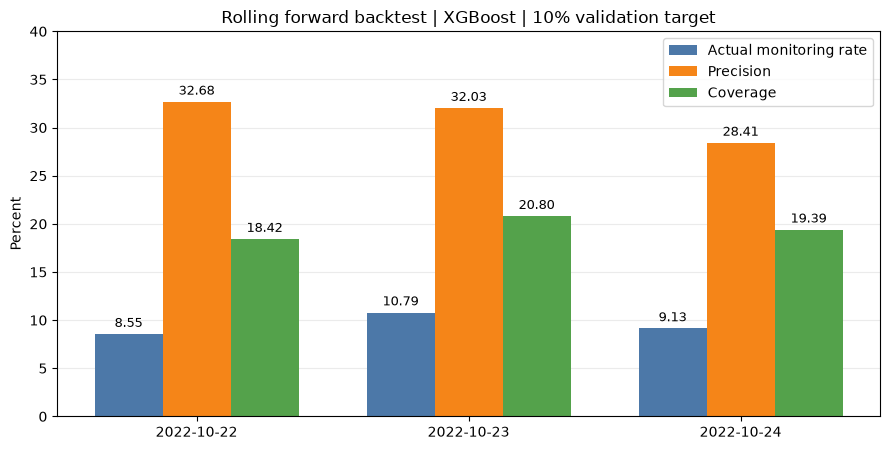

,fold,test_date,threshold,test_orders,test_late_pct,test_monitored,test_actual_pct,tp,precision_pct,coverage_pct,fpr_pct,fnr_pct,test_ap,test_roc_auc,test_brier
10,Fold 1,2022-10-22,0.2646,77637,15.1590,6635,8.5462,2168,32.6752,18.4213,6.7817,81.5787,0.2705,0.6793,0.1215
22,Fold 2,2022-10-23,0.2567,77719,16.6086,8384,10.7876,2685,32.0253,20.8011,8.7933,79.1989,0.2854,0.6740,0.1310
34,Fold 3,2022-10-24,0.2609,67349,13.3840,6152,9.1345,1748,28.4135,19.3921,7.5495,80.6079,0.2458,0.6808,0.1103


,method,test_orders,test_late_pct,test_monitored,test_actual_pct,tp,precision_pct,coverage_pct,fpr_pct,fnr_pct
37,Random,222705,15.1281,22283,10.0056,3379,15.1640,10.0294,10.0014,89.9706
40,Distance,222705,15.1281,22328,10.0258,4861,21.7709,14.4282,9.2411,85.5718
43,Logistic Regression,222705,15.1281,21453,9.6329,6283,29.2873,18.6489,8.0259,81.3511
46,XGBoost,222705,15.1281,21171,9.5063,6601,31.1794,19.5928,7.7084,80.4072


In [61]:
# 导出聚合指标；不保存滚动回测的逐单分数。
rolling_split_path = output_dir / "rolling_backtest_splits.csv"
rolling_metric_path = output_dir / "rolling_backtest_metrics.csv"
rolling_backtest_splits.to_csv(rolling_split_path, index=False, encoding="utf-8")
rolling_backtest_metrics.to_csv(rolling_metric_path, index=False, encoding="utf-8")

rolling_splits_read = pd.read_csv(rolling_split_path, float_precision="round_trip")
rolling_metrics_read = pd.read_csv(rolling_metric_path, float_precision="round_trip")
assert len(rolling_splits_read) == len(rolling_fold_specs)
assert len(rolling_metrics_read) == (
    len(rolling_fold_specs) * 4 * len(rolling_capacities)
    + 4 * len(rolling_capacities)
)
assert rolling_metrics_read.loc[
    rolling_metrics_read["scope"].eq("fold"), "test_orders"
].gt(0).all()
assert rolling_metrics_read.loc[
    rolling_metrics_read["scope"].eq("pooled_confusion"),
    ["test_ap", "test_roc_auc", "test_brier"],
].isna().all().all()

# 主业务容量下，展示 XGBoost 三个前瞻测试日的工作量和识别结果。
rolling_xgb_10 = rolling_backtest_metrics.loc[
    rolling_backtest_metrics["scope"].eq("fold")
    & rolling_backtest_metrics["method"].eq("XGBoost")
    & rolling_backtest_metrics["target_pct"].eq(10)
].copy()

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(rolling_xgb_10))
width = 0.25
for offset, column, label, color in [
    (-width, "test_actual_pct", "Actual monitoring rate", "#4c78a8"),
    (0, "precision_pct", "Precision", "#f58518"),
    (width, "coverage_pct", "Coverage", "#54a24b"),
]:
    bars = ax.bar(x + offset, rolling_xgb_10[column], width, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x, rolling_xgb_10["test_date"])
ax.set(
    ylabel="Percent",
    title="Rolling forward backtest | XGBoost | 10% validation target",
    ylim=(0, max(40, rolling_xgb_10[["precision_pct", "coverage_pct"]].to_numpy().max() + 6)),
)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

display(rolling_xgb_10[[
    "fold", "test_date", "threshold", "test_orders", "test_late_pct",
    "test_monitored", "test_actual_pct", "tp", "precision_pct", "coverage_pct",
    "fpr_pct", "fnr_pct", "test_ap", "test_roc_auc", "test_brier",
]].round(4))
display(
    rolling_backtest_metrics.loc[
        rolling_backtest_metrics["scope"].eq("pooled_confusion")
        & rolling_backtest_metrics["target_pct"].eq(10)
    ][[
        "method", "test_orders", "test_late_pct", "test_monitored",
        "test_actual_pct", "tp", "precision_pct", "coverage_pct",
        "fpr_pct", "fnr_pct",
    ]].round(4)
)

print(rolling_split_path)
print(rolling_metric_path)


XGBoost 在 10% 验证目标下的逐折测试结果为：

| 测试日 | 实际监控率 | 命中数 | 精确率 | 覆盖率 | AP |
|---|---:|---:|---:|---:|---:|
| 2022-10-22 | 8.55% | 2,168 | 32.68% | 18.42% | 0.27049 |
| 2022-10-23 | 10.79% | 2,685 | 32.03% | 20.80% | 0.28540 |
| 2022-10-24 | 9.13% | 1,748 | 28.41% | 19.39% | 0.24582 |

在每一折内，XGBoost 的 AP、10% 目标下的精确率和覆盖率均高于另外三种方法；各方法的实际监控量也有差异。三折 XGBoost 的实际监控率为 8.55%–10.79%，精确率为 28.41%–32.68%，覆盖率为 18.42%–20.80%。验证容量规则保持一致，逐日监控量随测试分数分布变化。

合并三日混淆矩阵计数后，共有 222,705 笔测试订单，XGBoost 命中 6,601 笔，实际监控率为 9.51%，精确率为 31.18%，覆盖率为 19.59%。这一汇总对应三个模型按各自阈值依次使用时的累计工作量和识别结果。AP、ROC-AUC 和 Brier 保留逐折报告，三折指标范围用于描述本次观察到的跨日波动。

主方案使历史训练和验证均覆盖工作日与周六，滚动回测记录了跨日工作量和识别表现的变化。各折的日期、训练样本量、模型和阈值同时变化；估计独立周末效应需要控制这些因素，长期预测表现需在新的时间窗口检验。


## 16. 主划分的随机种子敏感性

分组种子预先指定为 42、43、44，分别用于主方案和两次敏感性检查；模型参数、模型随机种子及外层测试日期保持固定。

In [62]:
# 三个预先声明的分组种子只用于检验开发集划分敏感性，不用于择优。
split_seeds = [42, 43, 44]
seed_sensitivity_rows = []
seed_test_boundary = pd.Timestamp("2022-10-23", tz="Asia/Shanghai")


def summarize_seed_test(seed, train_frame, validation_frame, threshold, scores):
    truth = df_test["y_0"].eq(1)
    alerted = scores.ge(threshold)
    tp = int((alerted & truth).sum())
    fp = int((alerted & ~truth).sum())
    fn = int((~alerted & truth).sum())
    tn = int((~alerted & ~truth).sum())
    monitored = tp + fp
    late_orders = tp + fn

    return {
        "split_seed": seed,
        "train_orders": len(train_frame),
        "validation_orders": len(validation_frame),
        "train_saturday_orders": int(train_frame["grab_date"].dt.day_of_week.eq(5).sum()),
        "validation_saturday_orders": int(
            validation_frame["grab_date"].dt.day_of_week.eq(5).sum()
        ),
        "threshold": threshold,
        "validation_actual_pct": np.nan,
        "test_orders": len(df_test),
        "test_late_pct": 100 * truth.mean(),
        "test_actual_pct": 100 * monitored / len(df_test),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "precision_pct": 100 * tp / monitored if monitored else np.nan,
        "coverage_pct": 100 * tp / late_orders if late_orders else np.nan,
        "fpr_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
        "fnr_pct": 100 * fn / late_orders if late_orders else np.nan,
        "ap": average_precision_score(truth, scores),
        "brier": brier_score_loss(truth, scores),
    }


# 主结果沿用已经完成全部诊断与导出核对的 seed=42 模型。
main_overall = dashboard_metrics.loc[dashboard_metrics["scope"].eq("overall")].iloc[0]
main_row = summarize_seed_test(
    42, df_train, df_val, threshold_10, test_scores["xgboost_score"]
)
main_row.update({
    "validation_actual_pct": (
        100 * validation_scores["xgboost_score"].ge(threshold_10).mean()
    ),
    "test_actual_pct": main_overall["actual_alert_pct"],
    "tp": int(main_overall["tp"]),
    "fp": int(main_overall["fp"]),
    "fn": int(main_overall["fn"]),
    "tn": int(main_overall["tn"]),
    "precision_pct": main_overall["precision_pct"],
    "coverage_pct": main_overall["coverage_pct"],
    "fpr_pct": main_overall["fpr_pct"],
    "fnr_pct": main_overall["fnr_pct"],
    "ap": main_overall["ap"],
    "brier": main_overall["brier"],
})
seed_sensitivity_rows.append(main_row)


for split_seed in split_seeds[1:]:
    seed_train, seed_validation = split_development(
        df_development, validation_fraction=0.2, random_state=split_seed
    )

    # 同一骑手同一接单日不能跨训练与验证，外层测试订单保持独立且更晚。
    seed_train_groups = set(zip(seed_train["courier_id"], seed_train["grab_date"]))
    seed_validation_groups = set(zip(
        seed_validation["courier_id"], seed_validation["grab_date"]
    ))
    assert seed_train_groups.isdisjoint(seed_validation_groups)
    assert set(seed_train["order_id"]).isdisjoint(seed_validation["order_id"])
    assert set(seed_train["order_id"]).isdisjoint(df_test["order_id"])
    assert set(seed_validation["order_id"]).isdisjoint(df_test["order_id"])
    assert seed_train["arrive_time_dt"].lt(seed_test_boundary).all()
    assert seed_validation["arrive_time_dt"].lt(seed_test_boundary).all()
    assert seed_train["grab_date"].lt(seed_test_boundary).all()
    assert seed_validation["grab_date"].lt(seed_test_boundary).all()
    assert df_test["grab_date"].ge(seed_test_boundary).all()

    seed_preprocessor = clone(preprocessor)
    seed_model = clone(xgb_model)
    seed_X_train = build_features(seed_train)
    seed_X_validation = build_features(seed_validation)
    seed_X_test = build_features(df_test)

    seed_train_ready = seed_preprocessor.fit_transform(seed_X_train)
    seed_validation_ready = seed_preprocessor.transform(seed_X_validation)
    seed_test_ready = seed_preprocessor.transform(seed_X_test)

    seed_model.fit(
        seed_train_ready.astype(np.float32).toarray(), seed_train["y_0"]
    )
    seed_validation_scores = pd.Series(
        seed_model.predict_proba(
            seed_validation_ready.astype(np.float32).toarray()
        )[:, 1],
        index=seed_validation.index,
    )
    seed_test_scores = pd.Series(
        seed_model.predict_proba(seed_test_ready.astype(np.float32).toarray())[:, 1],
        index=df_test.index,
    )

    seed_threshold, _ = choose_threshold(seed_validation_scores, capacity_pct=10)
    seed_row = summarize_seed_test(
        split_seed, seed_train, seed_validation, seed_threshold, seed_test_scores
    )
    seed_row["validation_actual_pct"] = (
        100 * seed_validation_scores.ge(seed_threshold).mean()
    )
    seed_sensitivity_rows.append(seed_row)


split_seed_sensitivity = pd.DataFrame(seed_sensitivity_rows).sort_values(
    "split_seed", ignore_index=True
)

# 三行共享同一外层测试期，反映划分敏感性，不是三个独立日期实验。
display(split_seed_sensitivity.round(5))

seed_output_path = Path("../results/split_seed_sensitivity.csv").resolve()
split_seed_sensitivity.to_csv(seed_output_path, index=False, encoding="utf-8")

seed_read = pd.read_csv(seed_output_path, float_precision="round_trip")
assert seed_read["split_seed"].tolist() == split_seeds
assert seed_read["test_orders"].eq(len(df_test)).all()
assert seed_read[["tp", "fp", "fn", "tn"]].sum(axis=1).eq(len(df_test)).all()
assert np.isclose(
    seed_read.loc[seed_read["split_seed"].eq(42), "threshold"].item(),
    threshold_10,
)
print(seed_output_path)


/Users/chronus/code/ai-bigdata-project/results/split_seed_sensitivity.csv


,split_seed,train_orders,validation_orders,train_saturday_orders,validation_saturday_orders,threshold,validation_actual_pct,test_orders,test_late_pct,test_actual_pct,tp,fp,fn,tn,precision_pct,coverage_pct,fpr_pct,fnr_pct,ap,brier
0,42,338252,84756,62132,15098,0.25734,10.00047,145068,15.11153,10.02495,4457,10086,17465,113060,30.64705,20.33117,8.19028,79.66883,0.26862,0.12128
1,43,338654,84354,61654,15576,0.25536,9.99953,145068,15.11153,10.36686,4587,10452,17335,112694,30.50070,20.92419,8.48749,79.07581,0.26837,0.12131
2,44,339488,83520,61730,15500,0.25678,10.00000,145068,15.11153,10.12422,4497,10190,17425,112956,30.61891,20.51364,8.27473,79.48636,0.26892,0.12128


| 分组种子 | 阈值 | 测试实际监控率 | 精确率 | 覆盖率 | AP |
|---|---:|---:|---:|---:|---:|
| 42 | 0.257345 | 10.02% | 30.65% | 20.33% | 0.26862 |
| 43 | 0.255355 | 10.37% | 30.50% | 20.92% | 0.26837 |
| 44 | 0.256781 | 10.12% | 30.62% | 20.51% | 0.26892 |

三个预先声明的分组种子下，精确率为 30.50%–30.65%，覆盖率为 20.33%–20.92%，AP 为 0.26837–0.26892。测试监控率随阈值变化为 10.02%–10.37%。这些结果描述本次分组扰动的范围，主结果始终采用预先指定的种子 42。

三次评价共用 10 月 23–24 日的同一批订单，变化来自开发集分组及随之重新拟合的模型和阈值。该范围衡量这一测试期内的分组敏感性；跨周不确定性的估计需要更多独立日期样本。


## 17. 结果与适用范围

在 10 月 23–24 日测试期，主方案 XGBoost 以 10.02% 的实际监控率识别 20.33% 的 `y_0` 晚到订单，预警精确率为 30.65%。4,457 笔命中中，4,376 笔相对于记录 ETA 仍有正提前量，其中 4,147 笔至少提前 15 分钟。这些回溯结果用于评估风险排序和潜在处置时间，实际干预收益需通过前瞻实验测量。

每日骑手分组使训练和验证都覆盖工作日及周六，三折回测进一步检查周五至周六、周六至周日和周日至周一的迁移。XGBoost 在各折的 AP 均高于三种比较方法，10% 目标下的覆盖率为 18.42%–20.80%，实际监控量也随日期变化。分组种子敏感性分析则描述同一测试期内，模型结果随开发集分组变化的幅度。

本次方案在查看早先测试结果后修订，采用回顾性设计。数据覆盖八个连续日期和一个周末；跨周、跨月份、节假日及其他运营条件下的表现需要新的时间窗口检验。标签截止规则排除了当时尚未完成的订单，样本范围为已接单且关键时间有效的记录。

字段在线读取时延和极端正耗时的业务含义需要结合业务日志核验。坐标距离描述近似地理跨度，分组误差和 SHAP 用于定位预测差异与复核对象。
